# Week 10 Project: Movie Recommendation System (MovieLens latest-small)
**Team name:** ____________ | **Members:** ____________ , ____________ | **Topic (ID and name):** P01 Movie recommender (MovieLens) | **Twist (if sharing a topic):** Time-based split instead of random, with a table showing how much a random split overstates quality (Section 8)

> **To do before you submit:** fill in the team name and members above, and complete the parts of the AI-use log in Section 14 that only you can write.

| # | Section | Done |
|---|---|---|
| 1 | Problem and users | [x] |
| 2 | Data | [x] |
| 3 | EDA | [x] |
| 4 | Baselines | [x] |
| 5 | Content-based model | [x] |
| 6 | Collaborative model | [x] |
| 7 | Matrix factorization (SVD) | [x] |
| 8 | Honest evaluation and results table | [x] |
| 9 | Cold start or hybrid | [x] (both) |
| 10 | Demo: recommend() | [x] |
| 11 | Break-it tests | [x] |
| 12 | By-hand check | [x] |
| 13 | Deliberate-leak experiment, decision log, bug log | [x] |
| 14 | AI-use log | [ ] partly: needs your own entries |

In [1]:
import os, time, zipfile, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.decomposition import TruncatedSVD

np.random.seed(1)
pd.set_option('display.precision', 4)
pd.set_option('display.width', 140)
os.makedirs('figures', exist_ok=True)      # plots are also saved here for the README
T0 = time.time()                            # used to report total run time at the end

## Helpers (tested, reuse them)
Ratings live in a **long table** with columns `user`, `item`, `rating` and optionally `time`. Rename your own columns to match.

*These helpers are copied unchanged from the starter notebook. The helper smoke-test cell was deleted after it ran, as the template asked.*

In [2]:
def split_ratings(df, test_frac=0.2, time_col=None, min_user_ratings=5, seed=1):
    """Split RATINGS (not users) into train and test.
    If time_col is given, each user's most recent test_frac of ratings go to test (time-based split).
    Otherwise a random split. Users with fewer than min_user_ratings ratings stay entirely in train."""
    rng = np.random.RandomState(seed)
    test_idx = []
    for u, g in df.groupby('user'):
        if len(g) < min_user_ratings:
            continue
        n_test = max(1, int(round(test_frac * len(g))))
        if time_col:
            test_idx += list(g.sort_values(time_col).index[-n_test:])
        else:
            test_idx += list(rng.choice(g.index, n_test, replace=False))
    test = df.loc[test_idx]
    train = df.drop(index=test_idx)
    return train.reset_index(drop=True), test.reset_index(drop=True)

def to_matrix(df, users=None, items=None):
    M = df.pivot_table(index='user', columns='item', values='rating', aggfunc='mean')
    if users is not None: M = M.reindex(index=users)
    if items is not None: M = M.reindex(columns=items)
    return M

def rmse(pred, true):
    pred, true = np.asarray(pred, float), np.asarray(true, float)
    return float(np.sqrt(np.mean((pred - true) ** 2)))

def precision_at_k(recommended, relevant, k):
    return len(set(recommended[:k]) & set(relevant)) / k

def recall_at_k(recommended, relevant, k):
    return len(set(recommended[:k]) & set(relevant)) / max(1, len(relevant))

def ndcg_at_k(recommended, relevant, k):
    gains = [1.0 / np.log2(i + 2) for i, it in enumerate(recommended[:k]) if it in set(relevant)]
    ideal = sum(1.0 / np.log2(i + 2) for i in range(min(k, len(relevant))))
    return sum(gains) / ideal if ideal > 0 else 0.0

def evaluate_topn(scores, train, test, k=10, rel_threshold=4):
    """scores: DataFrame (users x items) of predicted scores. Relevant = test ratings >= rel_threshold.
    Items the user already has in TRAIN are never recommended. Returns mean precision, recall, NDCG at k."""
    seen = train.groupby('user')['item'].apply(set).to_dict()
    rel = test[test.rating >= rel_threshold].groupby('user')['item'].apply(list).to_dict()
    P, R_, N = [], [], []
    for u, relevant in rel.items():
        if u not in scores.index: continue
        s = scores.loc[u].drop(labels=[i for i in seen.get(u, set()) if i in scores.columns], errors='ignore')
        rec = list(s.sort_values(ascending=False).index)
        P.append(precision_at_k(rec, relevant, k)); R_.append(recall_at_k(rec, relevant, k)); N.append(ndcg_at_k(rec, relevant, k))
    return {'users': len(P), f'precision@{k}': float(np.mean(P)), f'recall@{k}': float(np.mean(R_)), f'ndcg@{k}': float(np.mean(N))}

def svd_scores(R_train, k=10, seed=1):
    """Simple matrix factorization: centre by user mean, fill unrated with 0 (= no opinion), TruncatedSVD, add the mean back.
    A basic version for learning; libraries such as implicit or scikit-surprise are the next step."""
    means = R_train.mean(axis=1)
    C = R_train.sub(means, axis=0).fillna(0).values
    svd = TruncatedSVD(n_components=k, random_state=seed)
    U = svd.fit_transform(C)
    return pd.DataFrame(U @ svd.components_ + means.fillna(means.mean()).values[:, None], index=R_train.index, columns=R_train.columns)

### Extra helpers written for this project
The starter helpers above are reused as they are. The helpers below add what this project needs on top of them: a shared item-kNN scorer (used by both the content model and the collaborative model), per-pair rating lookup for RMSE, coverage, and a single `evaluate()` that puts every model on the **same test set**.

In [3]:
RATING_MIN, RATING_MAX = 0.5, 5.0   # MovieLens uses half stars from 0.5 to 5.0
K_EVAL = 5                          # main cut-off for precision@k, recall@k and NDCG@k (P01 card asks for @5)
REL_THRESHOLD = 4                   # a held-out rating >= 4 counts as "relevant" (a movie the user liked)

def predict_pairs(scores, pairs, clip=True):
    """Look up the predicted rating for every (user, item) row in `pairs` from a users x items score table."""
    r = scores.index.get_indexer(pairs.user)
    c = scores.columns.get_indexer(pairs.item)
    assert (r >= 0).all() and (c >= 0).all(), 'some test pairs are missing from the score table'
    p = scores.values[r, c]
    return np.clip(p, RATING_MIN, RATING_MAX) if clip else p

def coverage_at_k(scores, train, k=K_EVAL):
    """Share of the catalogue that appears in at least one user's top-k (unseen items only)."""
    seen = train.groupby('user')['item'].apply(set).to_dict()
    shown = set()
    for u in scores.index:
        s = scores.loc[u]
        s = s.drop(labels=[i for i in seen.get(u, set()) if i in s.index])
        shown.update(s.nlargest(k).index)
    return len(shown) / scores.shape[1]

def item_knn_scores(R, S, user_mean, k=20, damp=0.0):
    """Item-item neighbourhood prediction for EVERY (user, item) cell.
    R : users x items DataFrame of train ratings (NaN = not rated = no opinion)
    S : items x items numpy similarity matrix in the same item order as R.columns
    For user u and item i:  pred = mean_u + sum_j s(i,j) * (r_uj - mean_u) / sum_j s(i,j)
    where j runs over the k items RATED BY u with the largest POSITIVE similarity to i.
    If u has no such neighbour, pred = mean_u (fallback).
    damp > 0 adds a constant to the denominator: sum_j s(i,j) + damp. Predictions that rest on weak or few
    neighbours are pulled towards mean_u. This is used for the RANKING variant (Section 6b); damp=0 is the plain formula."""
    Rv = R.values
    S = S.astype(np.float32, copy=True)
    np.fill_diagonal(S, 0.0)                      # an item is never its own neighbour
    S[S < 0] = 0.0                                # keep positive neighbours only (as in the lab code)
    out = np.empty(Rv.shape, dtype=np.float64)
    for a, u in enumerate(R.index):
        mu = user_mean[u]
        rated = np.flatnonzero(~np.isnan(Rv[a]))
        if len(rated) == 0:
            out[a] = mu; continue
        dev = (Rv[a, rated] - mu).astype(np.float32)           # centred ratings of u
        Ssub = S[:, rated]                                      # similarity of every item to u's rated items
        if len(rated) > k:                                      # keep the top-k neighbours per target item
            idx = np.argpartition(-Ssub, k - 1, axis=1)[:, :k]
            Sk = np.take_along_axis(Ssub, idx, axis=1)
            Dk = dev[idx]
        else:
            Sk, Dk = Ssub, np.broadcast_to(dev, Ssub.shape)
        num, den = (Sk * Dk).sum(axis=1), Sk.sum(axis=1)
        out[a] = np.where(den > 0, mu + num / np.where(den > 0, den + damp, 1.0), mu)
    return pd.DataFrame(out, index=R.index, columns=R.columns)

def results_row(name, scores, ctx, k=K_EVAL, with_rmse=True):
    """One row of the results table: RMSE on the evaluation pairs + top-k ranking metrics + coverage."""
    row = {'model': name}
    row['RMSE'] = rmse(predict_pairs(scores, ctx['heldout']), ctx['heldout'].rating) if with_rmse else np.nan
    m = evaluate_topn(scores, ctx['train'], ctx['heldout'], k=k, rel_threshold=REL_THRESHOLD)
    row.update({f'precision@{k}': m[f'precision@{k}'], f'recall@{k}': m[f'recall@{k}'], f'ndcg@{k}': m[f'ndcg@{k}'],
                f'coverage@{k}': coverage_at_k(scores, ctx['train'], k), 'users': m['users']})
    return row

## 1. Problem and users
**User:** a viewer on a movie-streaming service (an OTT platform such as Netflix, Prime Video or Hotstar) who has already rated some films. **What is recommended:** films the viewer has not rated yet, as a ranked "top picks for you" row with a predicted star rating, plus "more like this" lists built from movie content. **Decision supported:** what to watch next. The system narrows thousands of titles down to a short list the viewer is likely to rate 4 stars or more, and gives a reason ("because you liked …"). The data is a MovieLens research sample, so this is an offline, academic version of that problem with no online A/B test.

## 2. Data
- **Source:** MovieLens latest-small (`ml-latest-small`), GroupLens Research, University of Minnesota: https://grouplens.org/datasets/movielens/latest/ (generated 26 September 2018; ratings from 29 March 1996 to 24 September 2018).
- **Licence:** GroupLens usage licence (in the dataset's `README.txt`). Research and educational use is allowed. Commercial use needs permission. Redistribution must keep the same licence. You must not imply endorsement. You must cite *F. M. Harper and J. A. Konstan (2015), "The MovieLens Datasets: History and Context", ACM TiiS 5(4)*. GroupLens calls this a *development* dataset, so the numbers below are course-project results, **not research findings**.
- **Files used:** `ratings.csv` (userId, movieId, rating, timestamp), `movies.csv` (movieId, title, genres), `tags.csv` (userId, movieId, tag, timestamp). `links.csv` (IMDb and TMDB ids) is loaded only to report its size, because no external metadata is joined in this project.
- **Size, sparsity and cleaning:** printed by the next cells from the real files. The cleaning steps and the reason for each are listed after the code.

In [4]:
# Load the data. Put the four CSV files in a folder called data/ next to this notebook.
# If they are missing (for example on a fresh Colab), they are downloaded from GroupLens once.
DATA_DIR = 'data'
URL = 'https://files.grouplens.org/datasets/movielens/ml-latest-small.zip'
if not os.path.exists(os.path.join(DATA_DIR, 'ratings.csv')):
    os.makedirs(DATA_DIR, exist_ok=True)
    print('Downloading', URL)
    zpath, _ = urllib.request.urlretrieve(URL, 'ml-latest-small.zip')
    with zipfile.ZipFile(zpath) as z:
        for name in z.namelist():
            if name.endswith('.csv') or name.endswith('README.txt'):
                with open(os.path.join(DATA_DIR, os.path.basename(name)), 'wb') as f:
                    f.write(z.read(name))

ratings_raw = pd.read_csv(os.path.join(DATA_DIR, 'ratings.csv'))
movies_raw  = pd.read_csv(os.path.join(DATA_DIR, 'movies.csv'))
tags_raw    = pd.read_csv(os.path.join(DATA_DIR, 'tags.csv'))
links_raw   = pd.read_csv(os.path.join(DATA_DIR, 'links.csv'))
for name, d in [('ratings', ratings_raw), ('movies', movies_raw), ('tags', tags_raw), ('links', links_raw)]:
    print(f'{name:8s} shape={d.shape}  columns={list(d.columns)}  missing values={int(d.isna().sum().sum())}  duplicate rows={int(d.duplicated().sum())}')
ratings_raw.head()

ratings  shape=(100836, 4)  columns=['userId', 'movieId', 'rating', 'timestamp']  missing values=0  duplicate rows=0
movies   shape=(9742, 3)  columns=['movieId', 'title', 'genres']  missing values=0  duplicate rows=0
tags     shape=(3683, 4)  columns=['userId', 'movieId', 'tag', 'timestamp']  missing values=0  duplicate rows=0
links    shape=(9742, 3)  columns=['movieId', 'imdbId', 'tmdbId']  missing values=8  duplicate rows=0


,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931


In [5]:
# ---- Cleaning ----
# 1) Rename to the long-table format the helpers expect: user, item, rating, time
ratings = ratings_raw.rename(columns={'userId': 'user', 'movieId': 'item', 'timestamp': 'time'})
print('duplicate (user, item) pairs:', int(ratings.duplicated(['user', 'item']).sum()))
print('ratings outside 0.5..5      :', int((~ratings.rating.between(RATING_MIN, RATING_MAX)).sum()))
print('rated movies missing from movies.csv:', int((~ratings.item.isin(movies_raw.movieId)).sum()))

# 2) Movies: keep the title for display, turn genres into tokens, mark "(no genres listed)" as empty
movies = movies_raw.rename(columns={'movieId': 'item'}).copy()
movies['genres'] = movies['genres'].replace('(no genres listed)', '')
print('movies with no genre listed :', int((movies.genres == '').sum()))
# 3) Duplicate titles: some titles appear twice with different movieIds. Add the id so the demo output is unambiguous
dup = movies.title.duplicated(keep=False)
print('titles shared by two movieIds:', int(dup.sum()), '->', sorted(movies.loc[dup, 'title'].unique()))
movies['display_title'] = np.where(dup, movies.title + ' [id ' + movies.item.astype(str) + ']', movies.title)
TITLE = movies.set_index('item')['display_title']

# 4) Tags: lower-case and strip spaces so 'Pixar' and 'pixar ' count as the same tag
tags = tags_raw.rename(columns={'userId': 'user', 'movieId': 'item', 'timestamp': 'time'}).copy()
tags['tag'] = tags['tag'].astype(str).str.lower().str.strip()
print('distinct tags before / after normalising:', tags_raw.tag.nunique(), '/', tags.tag.nunique())

n_users, n_items, n_ratings = ratings.user.nunique(), ratings.item.nunique(), len(ratings)
print(f'\nusers={n_users}  rated movies={n_items}  movies in catalogue file={len(movies)}  ratings={n_ratings}  tags={len(tags)}')
print('sparsity:', round(1 - n_ratings / (n_users * n_items), 4))
print('ratings per user: min', ratings.groupby('user').size().min(), '| median', int(ratings.groupby('user').size().median()),
      '| max', ratings.groupby('user').size().max())
print('date range:', pd.to_datetime(ratings.time.min(), unit='s').date(), 'to', pd.to_datetime(ratings.time.max(), unit='s').date())

duplicate (user, item) pairs: 0
ratings outside 0.5..5      : 0
rated movies missing from movies.csv: 0
movies with no genre listed : 34
titles shared by two movieIds: 10 -> ['Confessions of a Dangerous Mind (2002)', 'Emma (1996)', 'Eros (2004)', 'Saturn 3 (1980)', 'War of the Worlds (2005)']
distinct tags before / after normalising: 1589 / 1475

users=610  rated movies=9724  movies in catalogue file=9742  ratings=100836  tags=3683
sparsity: 0.983
ratings per user: min 20 | median 70 | max 2698
date range: 1996-03-29 to 2018-09-24


**Cleaning steps and why.** (1) The ratings file is renamed to `user, item, rating, time` so that the starter helpers can be reused. The checks above confirm it has no missing values, no duplicate user-movie pairs and no ratings off the 0.5 to 5 scale, so **no rating rows are dropped**. (2) `(no genres listed)` is turned into an empty genre string, so it does not become a fake shared "genre" token that makes unrelated movies look similar. (3) A few titles appear under two movieIds, so the display title gets the id added. This keeps the demo from showing two identical-looking lines. (4) Tags are lower-cased and stripped of spaces, so the same tag typed differently counts once in TF-IDF. **Unrated cells are never filled with 0 as a rating.** They stay `NaN` (= no opinion), and only after mean-centring is a 0 used, where it means "no deviation from this user's average".

## 3. EDA
Four plots: rating distribution, the long tail of ratings per movie, ratings per user, and how many ratings arrive per year (this matters for the time-based split).

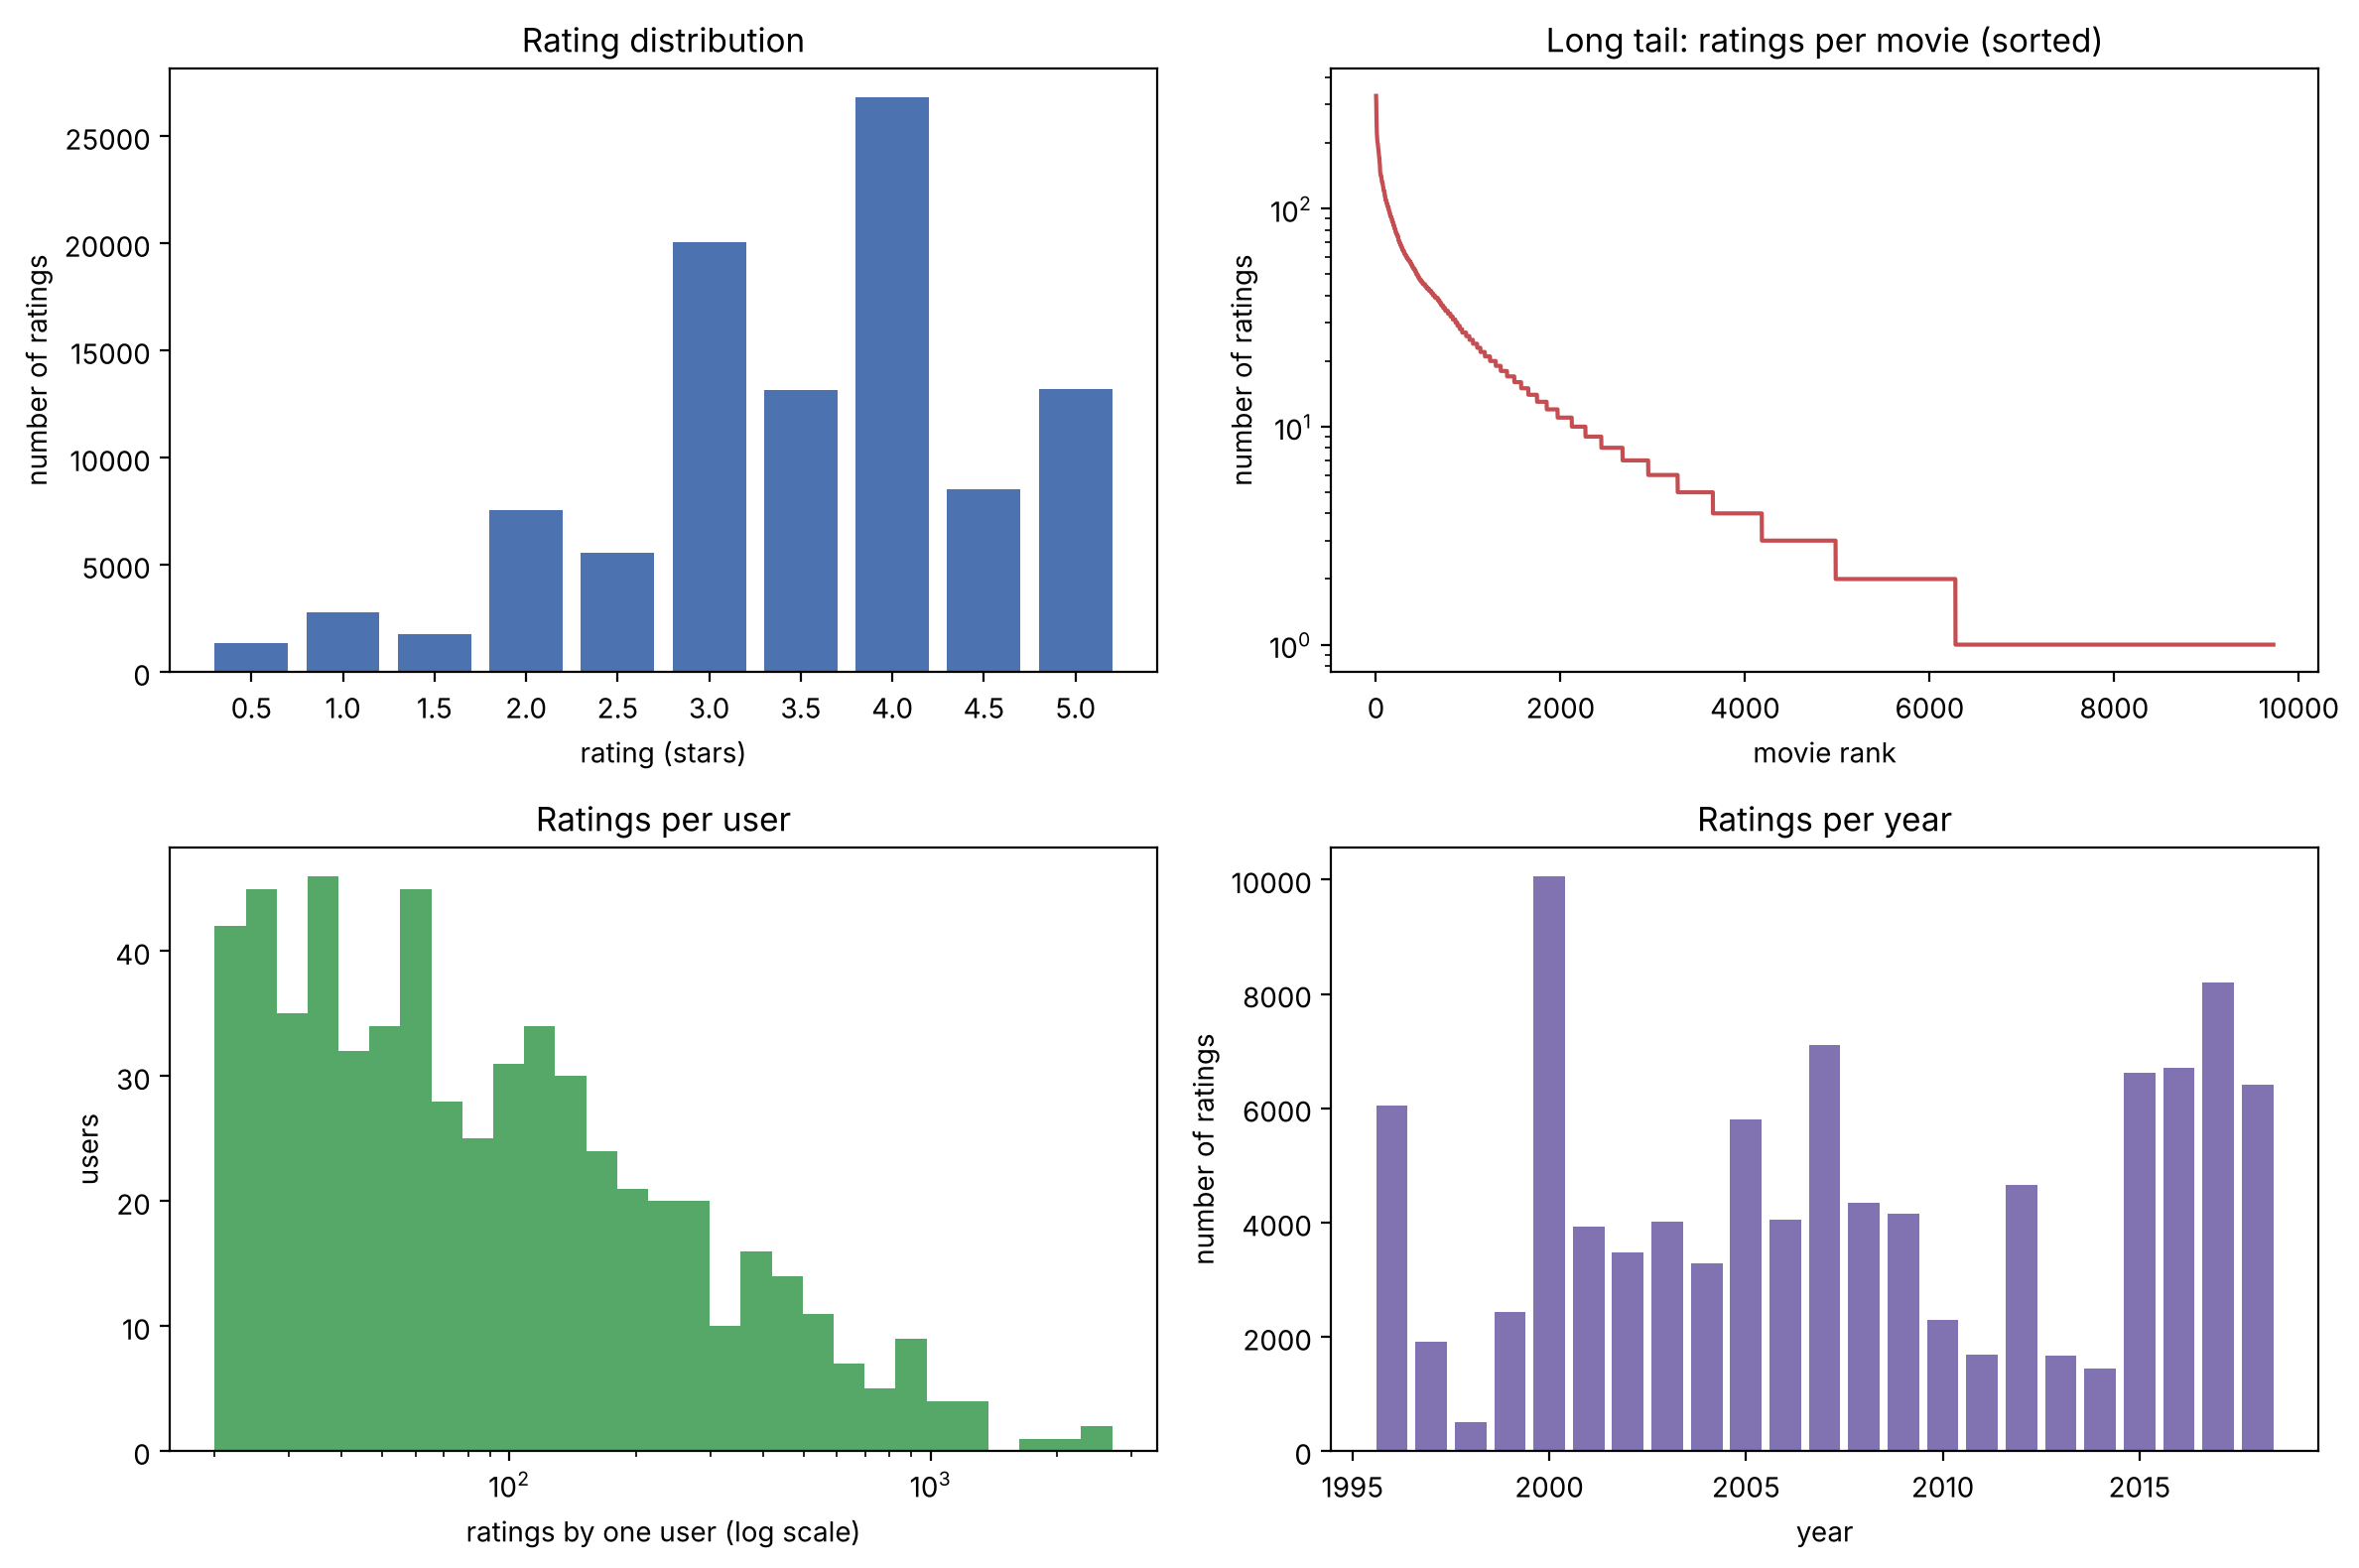

mean rating 3.502 | share of whole-star ratings 0.699
movies with exactly 1 rating: 3446 of 9724 (35.4%)
top 100 movies hold 16.1% of all ratings | median ratings per movie: 3
ratings >= 4 (counted as "liked"): 48.2%


In [6]:
fig, ax = plt.subplots(2, 2, figsize=(12, 8))
rc = ratings.rating.value_counts().sort_index()
ax[0, 0].bar(rc.index.astype(str), rc.values, color='#4C72B0')
ax[0, 0].set(title='Rating distribution', xlabel='rating (stars)', ylabel='number of ratings')

per_item = ratings.groupby('item').size().sort_values(ascending=False).values
ax[0, 1].plot(np.arange(1, len(per_item) + 1), per_item, color='#C44E52')
ax[0, 1].set(title='Long tail: ratings per movie (sorted)', xlabel='movie rank', ylabel='number of ratings', yscale='log')

per_user = ratings.groupby('user').size()
ax[1, 0].hist(per_user, bins=np.logspace(np.log10(20), np.log10(per_user.max()), 30), color='#55A868')
ax[1, 0].set(title='Ratings per user', xlabel='ratings by one user (log scale)', ylabel='users', xscale='log')

yr = pd.to_datetime(ratings.time, unit='s').dt.year.value_counts().sort_index()
ax[1, 1].bar(yr.index, yr.values, color='#8172B2')
ax[1, 1].set(title='Ratings per year', xlabel='year', ylabel='number of ratings')
plt.tight_layout(); plt.savefig('figures/eda.png', dpi=110); plt.show()

top100_share = per_item[:100].sum() / per_item.sum()
print(f'mean rating {ratings.rating.mean():.3f} | share of whole-star ratings {ratings.rating.isin([1,2,3,4,5]).mean():.3f}')
print(f'movies with exactly 1 rating: {(per_item == 1).sum()} of {len(per_item)} ({(per_item == 1).mean():.1%})')
print(f'top 100 movies hold {top100_share:.1%} of all ratings | median ratings per movie: {int(np.median(per_item))}')
print(f'ratings >= {REL_THRESHOLD} (counted as "liked"): {(ratings.rating >= REL_THRESHOLD).mean():.1%}')

**What the plots tell us about modelling.** (Each value below is printed by the cell above.)

- **Rating distribution.** Ratings lean positive. The mean is about 3.5 and 4.0 is the most common value. Whole stars are used much more than half stars. So the global mean is already a strong RMSE baseline, and errors are measured on a 0.5 to 5 scale that most users do not use in full. That is why each user's own average has to be removed (mean-centring) before comparing tastes.
- **Long tail.** The median movie has only 3 ratings and about a third of movies (35.4%) have exactly one, while the top 100 movies alone hold 16.1% of all ratings. Similarities for tail movies rest on one or two co-ratings and are mostly noise. So the collaborative model only scores movies with a minimum number of train ratings (a choice tuned in Section 6). Most-popular will be hard to beat on ranking metrics, so coverage has to be reported as well.
- **Ratings per user.** Every user has at least 20 ratings, but a few heavy users rated over 1,000 movies. Averaging metrics *per user* (as `evaluate_topn` does) stops heavy users from dominating the result.
- **Ratings per year.** Ratings arrive in bursts over 22 years. A random split would let the model train on a user's *future* ratings to predict their past ones, so the main evaluation uses a **time-based split** (each user's most recent 20% of ratings go to test).

## 4. Baselines
**Split first.** Every number from here on is fitted on `train` only. A second, validation split is cut **from train** (each user's latest 20% of train ratings). All tuning (k, SVD rank, hybrid weight, feature choices) is done on that validation split, so the test set is used only once, for the final table.

**Evaluation set.** Collaborative similarities need ratings to rest on. A movie is in the scoring **catalogue** if it has at least `MIN_ITEM_TRAIN` ratings in train (chosen in Section 6). Every model is scored on the same catalogue and the same held-out pairs. Test ratings for movies outside the catalogue (cold-start or very rare movies) are handled separately in Section 9.

In [7]:
MIN_ITEM_TRAIN = 5        # catalogue threshold (evidence in Section 6 and the decision log)

train, test = split_ratings(ratings, test_frac=0.2, time_col='time')          # final evaluation split
train_in, val = split_ratings(train, test_frac=0.2, time_col='time')          # tuning split, cut from TRAIN only
print(f'train {len(train)} | test {len(test)} | train_in {len(train_in)} | validation {len(val)}')

# sanity checks: no overlap, and every test rating is later than that user's train ratings
assert len(train.merge(test, on=['user', 'item'])) == 0
last_train = train.groupby('user').time.max(); first_test = test.groupby('user').time.min()
print('users whose test starts before their last train rating:', int((first_test < last_train.reindex(first_test.index)).sum()),
      '(only possible when timestamps tie)')

def make_context(tr, ho, min_item=MIN_ITEM_TRAIN):
    """Everything a model needs, computed from the TRAIN part only.
    tr = training ratings, ho = held-out ratings (validation or test)."""
    users = sorted(ratings.user.unique())
    R_all = to_matrix(tr, users=users, items=sorted(tr.item.unique()))      # users x every train movie
    user_mean = R_all.mean(axis=1)                                          # from train only
    counts = tr.groupby('item').size()
    catalog = sorted(counts[counts >= min_item].index)
    heldout = ho[ho.item.isin(catalog)].reset_index(drop=True)
    return dict(train=tr, heldout=heldout, heldout_all=ho, R_all=R_all, R=R_all[catalog], user_mean=user_mean,
                global_mean=float(tr.rating.mean()), catalog=catalog, counts=counts)

ctx_val  = make_context(train_in, val)
ctx_test = make_context(train, test)
for nm, c in [('validation', ctx_val), ('test', ctx_test)]:
    print(f"{nm:10s}: catalogue {len(c['catalog'])} movies | held-out pairs in catalogue {len(c['heldout'])} of {len(c['heldout_all'])}"
          f" | relevant (>= {REL_THRESHOLD}) {int((c['heldout'].rating >= REL_THRESHOLD).sum())}")

train 80672 | test 20164 | train_in 64549 | validation 16123
users whose test starts before their last train rating: 0 (only possible when timestamps tie)


validation: catalogue 2598 movies | held-out pairs in catalogue 12412 of 16123 | relevant (>= 4) 6019
test      : catalogue 3040 movies | held-out pairs in catalogue 15138 of 20164 | relevant (>= 4) 7524


In [8]:
def baseline_scores(ctx):
    """Global mean, user mean, item mean and most-popular score tables (users x catalogue), all from train."""
    users, cat = ctx['R'].index, ctx['catalog']
    g = ctx['global_mean']
    item_mean = ctx['train'].groupby('item').rating.mean().reindex(cat)
    pop = ctx['counts'].reindex(cat).astype(float)
    return {
        'global mean':  pd.DataFrame(g, index=users, columns=cat),
        'user mean':    pd.DataFrame(np.repeat(ctx['user_mean'].values[:, None], len(cat), 1), index=users, columns=cat),
        'item mean':    pd.DataFrame(np.repeat(item_mean.values[None, :], len(users), 0), index=users, columns=cat),
        'most popular': pd.DataFrame(np.repeat(pop.values[None, :], len(users), 0), index=users, columns=cat),
    }

base_test = baseline_scores(ctx_test)
rows = []
for name, sc in base_test.items():
    if name == 'most popular':
        rows.append(results_row(name, sc, ctx_test, with_rmse=False))          # a count is not a rating
    elif name in ('global mean', 'user mean'):
        r = results_row(name, sc, ctx_test)                                     # constant per user: ranking is meaningless
        r.update({f'precision@{K_EVAL}': np.nan, f'recall@{K_EVAL}': np.nan, f'ndcg@{K_EVAL}': np.nan, f'coverage@{K_EVAL}': np.nan})
        rows.append(r)
    else:
        rows.append(results_row(name, sc, ctx_test))
baseline_table = pd.DataFrame(rows).set_index('model')
baseline_table

,RMSE,precision@5,recall@5,ndcg@5,coverage@5,users
model,,,,,,
global mean,1.0403,NaN,NaN,NaN,NaN,586
user mean,0.9592,NaN,NaN,NaN,NaN,586
item mean,0.9698,0.0034,0.0007,0.0032,0.0033,586
most popular,NaN,0.0700,0.0326,0.0800,0.0191,586


**Reading the baselines.** Global mean and user mean give the same score to every movie for a given user, so they cannot rank anything and their ranking metrics are left empty. Most popular is a count, not a rating, so it has no RMSE. These rows set the bar. A model has to beat **user mean / item mean on RMSE** and **most popular on precision, recall and NDCG** to be worth anything.

## 5. Content-based model
**Item features:** each movie's genres (as tokens such as `genre_sci_fi`) plus the free-text tags users attached to it. TF-IDF turns this into a vector. Words that occur in few movies get more weight. **Leakage guard:** the TF-IDF vocabulary is fitted on movie text only, never on ratings. Any tag that a user attached to a movie in **that user's held-out set** is removed, because tagging a movie reveals that the user watched it.

Two ways of using the vectors:
1. **Item-kNN on content similarity** (predicts a star rating): the same formula as item-based CF, but the similarity comes from TF-IDF cosine instead of co-ratings.
2. **User profile** (ranking only, as in the lab): profile = sum of the vectors of the movies the user rated, weighted by *rating minus the user's mean*. Unseen movies are scored by cosine similarity to the profile.

In [9]:
def genre_tokens(g):
    return ' '.join('genre_' + x.lower().replace('-', '_').replace(' ', '_') for x in g.split('|') if x)

def build_item_text(exclude_pairs=None, use_tags=True):
    """One text field per movie in movies.csv: genre tokens + tags. exclude_pairs = held-out (user, item) pairs whose tags are dropped."""
    t = tags
    if exclude_pairs is not None:
        key = set(zip(exclude_pairs.user, exclude_pairs.item))
        keep = [(u, i) not in key for u, i in zip(t.user, t.item)]
        t = t[keep]
    tag_text = t.groupby('item').tag.apply(lambda s: ' '.join(s)) if use_tags else pd.Series(dtype=str)
    text = movies.set_index('item').genres.map(genre_tokens)
    return (text + ' ' + tag_text.reindex(text.index).fillna('')).str.strip(), (len(tags) - len(t))

def fit_tfidf(text):
    """Fit TF-IDF on movie text only (never ratings). Returns the fitted vectoriser and the movie x term matrix."""
    vec = TfidfVectorizer(token_pattern=r'[a-z0-9_]+', stop_words='english', sublinear_tf=True)
    X = vec.fit_transform(text.values)
    return vec, pd.Index(text.index), X

def content_sim(X, item_index, items):
    """Cosine similarity between the TF-IDF vectors of `items` (dense numpy, same order as items)."""
    rows = item_index.get_indexer(items)
    return cosine_similarity(X[rows]).astype(np.float32)

def profile_scores(ctx, X, item_index):
    """Content user profiles: weight = rating - user mean (from train). Score = cosine(profile, movie vector)."""
    R_all, mu = ctx['R_all'], ctx['user_mean']
    W = R_all.sub(mu, axis=0).fillna(0.0)                                    # unrated -> 0 weight (no opinion)
    Xr = X[item_index.get_indexer(R_all.columns)]
    P = sparse.csr_matrix(W.values) @ Xr                                     # users x terms
    Xc = X[item_index.get_indexer(ctx['catalog'])]
    return pd.DataFrame(cosine_similarity(P, Xc), index=R_all.index, columns=ctx['catalog'])

text_val, dropped_val = build_item_text(exclude_pairs=val)
text_test, dropped_test = build_item_text(exclude_pairs=test)
print('tags removed because they sit on held-out pairs: validation', dropped_val, '| test', dropped_test)
vec_test, IDX_TEST, X_test = fit_tfidf(text_test)
print('TF-IDF vocabulary size (test setting):', len(vec_test.vocabulary_), '| movies vectorised:', X_test.shape[0])
print('movies in the test catalogue with at least one tag:', int(pd.Index(ctx_test['catalog']).isin(tags.item).sum()),
      'of', len(ctx_test['catalog']))

# quick look: content neighbours of a well-known movie
probe = movies.loc[movies.title.str.startswith('Toy Story (1995)'), 'item'].iloc[0]
s = pd.Series(cosine_similarity(X_test[IDX_TEST.get_loc(probe)], X_test).ravel(), index=IDX_TEST)
print('\nContent neighbours of', TITLE[probe], '->', [TITLE[i] for i in s.drop(probe).nlargest(5).index])

tags removed because they sit on held-out pairs: validation 372 | test 815
TF-IDF vocabulary size (test setting): 1378 | movies vectorised: 9742
movies in the test catalogue with at least one tag: 1048 of 3040

Content neighbours of Toy Story (1995) -> ['Toy Story 2 (1999)', "Bug's Life, A (1998)", 'Guardians of the Galaxy 2 (2017)', 'Antz (1998)', 'Adventures of Rocky and Bullwinkle, The (2000)']


In [10]:
# Tuning on the VALIDATION split: features (genres only vs genres + tags) and k for content item-kNN
vec_v, IDX_V, X_v = fit_tfidf(text_val)
_, IDX_Vg, X_vg = fit_tfidf(build_item_text(exclude_pairs=val, use_tags=False)[0])
cb_tune = []
for feat, (Xf, idxf) in {'genres only': (X_vg, IDX_Vg), 'genres + tags': (X_v, IDX_V)}.items():
    S_cb_v = content_sim(Xf, idxf, ctx_val['catalog'])
    for k in [10, 20, 40, 80]:
        sc = item_knn_scores(ctx_val['R'], S_cb_v, ctx_val['user_mean'], k=k)
        r = results_row(f'CB {feat} k={k}', sc, ctx_val)
        cb_tune.append({'features': feat, 'k': k, 'val RMSE': r['RMSE'], f'val ndcg@{K_EVAL}': r[f'ndcg@{K_EVAL}']})
cb_tune = pd.DataFrame(cb_tune)
print(cb_tune.to_string(index=False))
best = cb_tune.sort_values('val RMSE').iloc[0]
K_CB, CB_FEATURES = int(best.k), best.features
print(f'\nchosen for the content model: features = {CB_FEATURES}, k = {K_CB} (lowest validation RMSE)')

     features  k  val RMSE  val ndcg@5
  genres only 10    0.9347      0.0084
  genres only 20    0.9198      0.0082
  genres only 40    0.9143      0.0052
  genres only 80    0.9136      0.0034
genres + tags 10    0.9256      0.0165
genres + tags 20    0.9114      0.0118
genres + tags 40    0.9097      0.0085
genres + tags 80    0.9113      0.0068

chosen for the content model: features = genres + tags, k = 40 (lowest validation RMSE)


In [11]:
# Fit the chosen content model on TRAIN and score the test catalogue
if CB_FEATURES == 'genres only':
    vec_test, IDX_TEST, X_test = fit_tfidf(build_item_text(exclude_pairs=test, use_tags=False)[0])
S_cb_test = content_sim(X_test, IDX_TEST, ctx_test['catalog'])
cb_test = item_knn_scores(ctx_test['R'], S_cb_test, ctx_test['user_mean'], k=K_CB)
cbp_test = profile_scores(ctx_test, X_test, IDX_TEST)
print(pd.DataFrame([results_row('content item-kNN', cb_test, ctx_test),
                    results_row('content user-profile', cbp_test, ctx_test, with_rmse=False)]).set_index('model'))

                        RMSE  precision@5  recall@5  ndcg@5  coverage@5  users
model                                                                         
content item-kNN      0.9297       0.0174    0.0050  0.0157      0.1526    586
content user-profile     NaN       0.0123    0.0059  0.0133      0.3234    586


## 6. Collaborative model
**Item-based CF with mean-centred (adjusted) cosine.** Each user's mean (from train) is subtracted from their ratings. Unrated cells then become 0, which here means *no opinion* (no deviation from the user's average), **not** a zero-star rating. Movie-movie similarity is the cosine between the centred columns. Prediction:

$$\hat r_{u,i}=\bar r_u+\frac{\sum_{j\in N_k(i;u)} s(i,j)\,(r_{u,j}-\bar r_u)}{\sum_{j\in N_k(i;u)} |s(i,j)|}$$

Here $N_k(i;u)$ is the set of the $k$ movies **rated by $u$** with the highest positive similarity to $i$. An optional *shrinkage* term $s\cdot\frac{n_{ij}}{n_{ij}+\beta}$ ($n_{ij}$ = number of users who rated both) damps similarities that rest on very few co-raters.

All choices below (centred vs raw cosine, k, shrinkage, catalogue threshold) are made on the **validation** split.

In [12]:
def item_cf_similarity(R, user_mean, centred=True, shrink=0.0):
    """Movie x movie cosine similarity from TRAIN ratings.
    centred=True : subtract each user's mean first (adjusted cosine); unrated -> 0 = no opinion.
    centred=False: raw cosine with unrated filled by 0 (the classic mistake from the lab's Deliberate error 2)."""
    M = R.sub(user_mean, axis=0).fillna(0.0) if centred else R.fillna(0.0)
    Ms = sparse.csr_matrix(M.values.astype(np.float32))
    S = cosine_similarity(Ms.T, dense_output=True).astype(np.float32)
    if shrink > 0:
        B = sparse.csr_matrix(R.notna().values.astype(np.float32))
        n_co = (B.T @ B).toarray()                                  # number of users who rated both movies
        S *= n_co / (n_co + shrink)
    return S

t = time.time()
cf_tune = []
for centred in [False, True]:
    S0 = item_cf_similarity(ctx_val['R'], ctx_val['user_mean'], centred=centred)
    for k in [5, 10, 20, 40, 80]:
        sc = item_knn_scores(ctx_val['R'], S0, ctx_val['user_mean'], k=k)
        r = results_row('', sc, ctx_val)
        cf_tune.append({'similarity': 'centred cosine' if centred else 'raw cosine (gaps=0)', 'shrink': 0, 'k': k,
                        'val RMSE': r['RMSE'], f'val ndcg@{K_EVAL}': r[f'ndcg@{K_EVAL}']})
cf_tune = pd.DataFrame(cf_tune)
print(cf_tune.to_string(index=False))
print(f'({time.time() - t:.0f}s)')

         similarity  shrink  k  val RMSE  val ndcg@5
raw cosine (gaps=0)       0  5    0.9062      0.0246
raw cosine (gaps=0)       0 10    0.8773      0.0264
raw cosine (gaps=0)       0 20    0.8748      0.0289
raw cosine (gaps=0)       0 40    0.8812      0.0250
raw cosine (gaps=0)       0 80    0.8918      0.0136
     centred cosine       0  5    0.8960      0.0158
     centred cosine       0 10    0.8718      0.0163
     centred cosine       0 20    0.8607      0.0191
     centred cosine       0 40    0.8583      0.0123
     centred cosine       0 80    0.8594      0.0069
(23s)


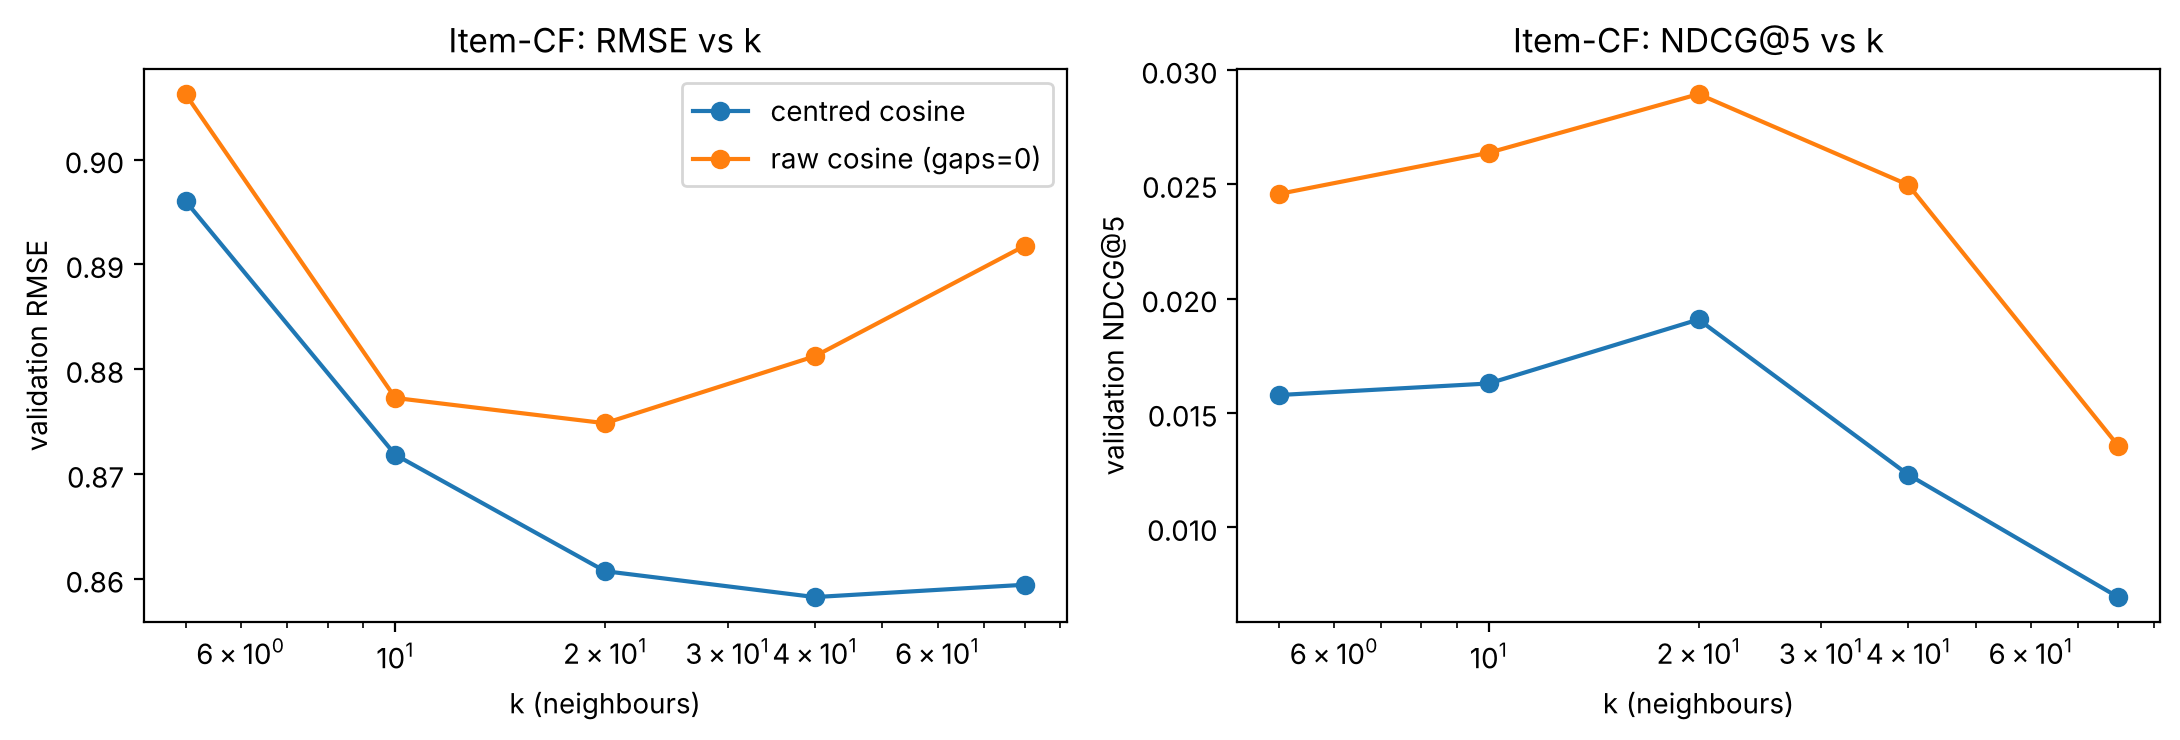

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for simname, g in cf_tune.groupby('similarity'):
    ax[0].plot(g.k, g['val RMSE'], marker='o', label=simname)
    ax[1].plot(g.k, g[f'val ndcg@{K_EVAL}'], marker='o', label=simname)
ax[0].set(xscale='log', xlabel='k (neighbours)', ylabel='validation RMSE', title='Item-CF: RMSE vs k')
ax[1].set(xscale='log', xlabel='k (neighbours)', ylabel=f'validation NDCG@{K_EVAL}', title=f'Item-CF: NDCG@{K_EVAL} vs k')
ax[0].legend(); plt.tight_layout(); plt.savefig('figures/cf_k.png', dpi=110); plt.show()

In [14]:
# Shrinkage and catalogue threshold, with centred cosine and the best k from above
K_CF = int(cf_tune[cf_tune.similarity == 'centred cosine'].sort_values('val RMSE').iloc[0].k)
shr = []
S_c = item_cf_similarity(ctx_val['R'], ctx_val['user_mean'], centred=True)
B = sparse.csr_matrix(ctx_val['R'].notna().values.astype(np.float32)); N_CO = (B.T @ B).toarray()
for beta in [0, 10, 25, 50, 100]:
    S_b = S_c * (N_CO / (N_CO + beta)) if beta > 0 else S_c
    r = results_row('', item_knn_scores(ctx_val['R'], S_b, ctx_val['user_mean'], k=K_CF), ctx_val)
    shr.append({'shrink beta': beta, 'val RMSE': r['RMSE'], f'val ndcg@{K_EVAL}': r[f'ndcg@{K_EVAL}']})
shr = pd.DataFrame(shr); print(f'k = {K_CF}'); print(shr.to_string(index=False))
SHRINK = int(shr.sort_values('val RMSE').iloc[0]['shrink beta'])
del N_CO, B

# Catalogue threshold: compare on the SAME validation pairs (movies with >= 10 train ratings, so that every threshold can score them)
thr = []
pairs10 = val[val.item.isin(make_context(train_in, val, min_item=10)['catalog'])]   # pairs every threshold can score
for m in [3, 5, 10]:
    c = make_context(train_in, val, min_item=m)
    S_m = item_cf_similarity(c['R'], c['user_mean'], centred=True, shrink=SHRINK)
    sc = item_knn_scores(c['R'], S_m, c['user_mean'], k=K_CF)
    thr.append({'min train ratings per movie': m, 'catalogue size': len(c['catalog']),
                'val RMSE on common pairs': rmse(predict_pairs(sc, pairs10), pairs10.rating),
                'similarity matrix MB': round(S_m.nbytes / 1e6, 1)})
thr = pd.DataFrame(thr); print(); print(thr.to_string(index=False))
print(f'\nchosen: centred cosine, k = {K_CF}, shrinkage beta = {SHRINK}, catalogue threshold = {MIN_ITEM_TRAIN}')

k = 40
 shrink beta  val RMSE  val ndcg@5
           0    0.8583      0.0123
          10    0.8599      0.0096
          25    0.8614      0.0098
          50    0.8626      0.0096
         100    0.8632      0.0109



 min train ratings per movie  catalogue size  val RMSE on common pairs  similarity matrix MB
                           3            3574                    0.8503                  51.1
                           5            2598                    0.8497                  27.0
                          10            1538                    0.8503                   9.5

chosen: centred cosine, k = 40, shrinkage beta = 0, catalogue threshold = 5


In [15]:
# Final item-CF fitted on TRAIN with the chosen settings, scored on the test catalogue
t = time.time()
S_cf_test = item_cf_similarity(ctx_test['R'], ctx_test['user_mean'], centred=True, shrink=SHRINK)
cf_test = item_knn_scores(ctx_test['R'], S_cf_test, ctx_test['user_mean'], k=K_CF)
S_raw_test = item_cf_similarity(ctx_test['R'], ctx_test['user_mean'], centred=False)
cf_raw_test = item_knn_scores(ctx_test['R'], S_raw_test, ctx_test['user_mean'], k=K_CF)
del S_raw_test
print(pd.DataFrame([results_row('item-CF centred cosine', cf_test, ctx_test),
                    results_row('item-CF raw cosine (gaps=0)', cf_raw_test, ctx_test)]).set_index('model'))
print(f'({time.time() - t:.0f}s)')

                               RMSE  precision@5  recall@5  ndcg@5  coverage@5  users
model                                                                                
item-CF centred cosine       0.8662       0.0205    0.0028  0.0190      0.3664    586
item-CF raw cosine (gaps=0)  0.8938       0.0239    0.0049  0.0256      0.2691    586
(7s)


### 6b. A problem found: low RMSE, poor ranking (and the fix)
The table above shows that item-CF has the best RMSE so far but a much **lower** NDCG@5 than *most popular*. Its top-5 lists were full of rarely rated movies. The reason is in the formula: the denominator normalises the weights, so a movie with **one** weakly similar neighbour that the user loved is predicted just as high as a movie backed by 40 strongly similar neighbours. Such "single-neighbour 5-star" predictions crowd the top of the list.

**Fix (ranking variant):** add a damping constant λ to the denominator, $\sum_j s(i,j) + \lambda$. Predictions that rest on little evidence shrink towards the user's mean, so well-supported movies rise to the top. RMSE is expected to get slightly worse, because predictions move towards the mean. k and λ are chosen by **validation NDCG@5**. The plain formula (λ = 0) stays the rating-prediction model.

In [16]:
rank_tune = []
S_c_val = item_cf_similarity(ctx_val['R'], ctx_val['user_mean'], centred=True, shrink=SHRINK)
for k in [10, 20, 40]:
    for lam in [0, 1, 2, 5, 10, 20]:
        r = results_row('', item_knn_scores(ctx_val['R'], S_c_val, ctx_val['user_mean'], k=k, damp=lam), ctx_val)
        rank_tune.append({'k': k, 'damp lambda': lam, 'val RMSE': r['RMSE'], f'val precision@{K_EVAL}': r[f'precision@{K_EVAL}'],
                          f'val ndcg@{K_EVAL}': r[f'ndcg@{K_EVAL}'], f'val coverage@{K_EVAL}': r[f'coverage@{K_EVAL}']})
rank_tune = pd.DataFrame(rank_tune); print(rank_tune.round(4).to_string(index=False))
best = rank_tune.sort_values(f'val ndcg@{K_EVAL}', ascending=False).iloc[0]
K_RANK, DAMP = int(best.k), float(best['damp lambda'])
print(f'\nchosen ranking variant: k = {K_RANK}, lambda = {DAMP} (highest validation NDCG@{K_EVAL})')

# same damping idea for the content model (k fixed at K_CB), tuned on validation NDCG
X_cb_val, IDX_cb_val = (X_v, IDX_V) if CB_FEATURES != 'genres only' else (X_vg, IDX_Vg)
S_cb_val = content_sim(X_cb_val, IDX_cb_val, ctx_val['catalog'])
cb_rank_tune = []
for lam in [0, 1, 2, 5, 10, 20]:
    r = results_row('', item_knn_scores(ctx_val['R'], S_cb_val, ctx_val['user_mean'], k=K_CB, damp=lam), ctx_val)
    cb_rank_tune.append({'damp lambda': lam, 'val RMSE': r['RMSE'], f'val ndcg@{K_EVAL}': r[f'ndcg@{K_EVAL}']})
cb_rank_tune = pd.DataFrame(cb_rank_tune); print(cb_rank_tune.round(4).to_string(index=False))
DAMP_CB = float(cb_rank_tune.sort_values(f'val ndcg@{K_EVAL}', ascending=False).iloc[0]['damp lambda'])
print('chosen content damping:', DAMP_CB)
del S_c_val

cf_rank_test = item_knn_scores(ctx_test['R'], S_cf_test, ctx_test['user_mean'], k=K_RANK, damp=DAMP)
cb_rank_test = item_knn_scores(ctx_test['R'], S_cb_test, ctx_test['user_mean'], k=K_CB, damp=DAMP_CB)
print(pd.DataFrame([results_row('item-CF plain (lambda=0)', cf_test, ctx_test),
                    results_row(f'item-CF ranking variant (k={K_RANK}, lambda={DAMP})', cf_rank_test, ctx_test)]).set_index('model').round(4))

 k  damp lambda  val RMSE  val precision@5  val ndcg@5  val coverage@5
10            0    0.8718           0.0169      0.0163          0.4842
10            1    0.8704           0.0438      0.0506          0.4080
10            2    0.8789           0.0531      0.0616          0.3703
10            5    0.8974           0.0590      0.0687          0.3445
10           10    0.9117           0.0593      0.0705          0.3226
10           20    0.9226           0.0607      0.0723          0.3129
20            0    0.8607           0.0190      0.0191          0.4349
20            1    0.8644           0.0507      0.0581          0.4338
20            2    0.8719           0.0579      0.0692          0.3907
20            5    0.8886           0.0693      0.0810          0.3557
20           10    0.9036           0.0686      0.0813          0.3345
20           20    0.9166           0.0659      0.0801          0.3195
40            0    0.8583           0.0131      0.0123          0.4034
40    

 damp lambda  val RMSE  val ndcg@5
           0    0.9097      0.0085
           1    0.9065      0.0132
           2    0.9075      0.0155
           5    0.9108      0.0176
          10    0.9150      0.0157
          20    0.9200      0.0151
chosen content damping: 5.0


                                               RMSE  precision@5  recall@5  ndcg@5  coverage@5  users
model                                                                                                
item-CF plain (lambda=0)                     0.8662       0.0205    0.0028  0.0190      0.3664    586
item-CF ranking variant (k=20, lambda=10.0)  0.9198       0.0655    0.0287  0.0696      0.2987    586


**Why centring matters (P01 concept).** With raw ratings and gaps filled with 0, every rating is positive, so almost every pair of movies looks similar. A movie loved by one user and hated by another still gets a high similarity, because "rated by the same people" is all the raw cosine sees. After centring, a below-average rating becomes negative, so the similarity can be negative and tells "same taste" apart from "same audience". On RMSE the numbers agree: validation RMSE is 0.8583 for centred vs 0.8748 for raw at their best k, and test RMSE is 0.8662 vs 0.8938. **But** raw cosine gets a slightly higher NDCG@5 (test 0.0256 vs 0.0190). Raw similarity mostly measures "watched by the same people", which is close to popularity, and popularity is what this time split rewards (see Section 8). Centring is chosen because the model's job here is rating prediction, and the ranking weakness is fixed separately in 6b.

**Effect of k.** Very small k averages over 5 neighbours, which is noisy. Larger k smooths the prediction towards the user's mean. The curve flattens after the chosen k. The exact numbers are in the tuning table and the decision log.

## 7. Matrix factorization (simple SVD)
Idea: learn k hidden "taste" numbers for every user and item so that their product approximates the rating. Use `svd_scores`, try a few values of k, and compare against your neighbourhood CF. In two sentences, say how this differs from neighbourhood CF.

*How it differs:* neighbourhood CF predicts from a handful of explicit neighbours (the k most similar movies the user rated), so each prediction can be explained by named movies. SVD compresses the **whole** centred rating matrix into a few latent factors shared by all users and movies, so it can link two movies that were never co-rated, but its factors have no names. Note that this simple SVD treats unrated cells as 0 = "no deviation from the user mean" during fitting, which pulls predictions towards the mean. Models such as ALS or FunkSVD fit only the observed cells.

In [17]:
svd_tune = []
for k in [2, 5, 10, 20, 50]:
    sc = svd_scores(ctx_val['R_all'], k=k)[ctx_val['catalog']]           # fitted on train_in only
    r = results_row('', sc, ctx_val)
    svd_tune.append({'SVD rank k': k, 'val RMSE': r['RMSE'], f'val ndcg@{K_EVAL}': r[f'ndcg@{K_EVAL}']})
svd_tune = pd.DataFrame(svd_tune); print(svd_tune.to_string(index=False))
K_SVD = int(svd_tune.sort_values('val RMSE').iloc[0]['SVD rank k'])
print('chosen SVD rank:', K_SVD)

svd_test = svd_scores(ctx_test['R_all'], k=K_SVD)[ctx_test['catalog']]   # fitted on train only
print(pd.DataFrame([results_row(f'SVD k={K_SVD}', svd_test, ctx_test),
                    results_row('item-CF centred cosine', cf_test, ctx_test)]).set_index('model'))

 SVD rank k  val RMSE  val ndcg@5
          2    0.9155      0.0586
          5    0.9143      0.0724
         10    0.9146      0.0811
         20    0.9170      0.0915
         50    0.9241      0.0846
chosen SVD rank: 5


                          RMSE  precision@5  recall@5  ndcg@5  coverage@5  users
model                                                                           
SVD k=5                 0.9324       0.0778    0.0309  0.0848      0.0655    586
item-CF centred cosine  0.8662       0.0205    0.0028  0.0190      0.3664    586


## 8. Honest evaluation and results table
Every row below uses the **same** time-based test set (each user's most recent 20% of ratings, restricted to the catalogue of movies with ≥ `MIN_ITEM_TRAIN` train ratings), the same train-only fitting, and the same rule that movies the user rated in train are never recommended. RMSE is computed on predictions clipped to the 0.5 to 5 scale. The hybrid row uses the weight α tuned on the validation split (Section 9). It is placed here so that every model sits in one table.

In [18]:
# Hybrid blend of item-CF and content item-kNN, alpha tuned on VALIDATION (details in Section 9)
S_cf_val = item_cf_similarity(ctx_val['R'], ctx_val['user_mean'], centred=True, shrink=SHRINK)
cf_val = item_knn_scores(ctx_val['R'], S_cf_val, ctx_val['user_mean'], k=K_CF)
cb_val = item_knn_scores(ctx_val['R'], content_sim(X_v if CB_FEATURES != 'genres only' else X_vg,
                         IDX_V if CB_FEATURES != 'genres only' else IDX_Vg, ctx_val['catalog']), ctx_val['user_mean'], k=K_CB)
alpha_tune = []
for a in np.round(np.arange(0, 1.01, 0.1), 1):
    r = results_row('', a * cf_val + (1 - a) * cb_val, ctx_val)
    alpha_tune.append({'alpha (CF weight)': a, 'val RMSE': r['RMSE'], f'val ndcg@{K_EVAL}': r[f'ndcg@{K_EVAL}']})
alpha_tune = pd.DataFrame(alpha_tune)
ALPHA = float(alpha_tune.sort_values('val RMSE').iloc[0]['alpha (CF weight)'])
hyb_test = ALPHA * cf_test + (1 - ALPHA) * cb_test

# ranking hybrid: blend of the two DAMPED scorers, weight tuned on validation NDCG
cf_val_r = item_knn_scores(ctx_val['R'], S_cf_val, ctx_val['user_mean'], k=K_RANK, damp=DAMP)
cb_val_r = item_knn_scores(ctx_val['R'], S_cb_val, ctx_val['user_mean'], k=K_CB, damp=DAMP_CB)
for row, a in zip(alpha_tune.itertuples(), alpha_tune['alpha (CF weight)']):
    alpha_tune.loc[row.Index, f'val ndcg@{K_EVAL} (damped blend)'] = results_row('', a * cf_val_r + (1 - a) * cb_val_r, ctx_val)[f'ndcg@{K_EVAL}']
ALPHA_RANK = float(alpha_tune.sort_values(f'val ndcg@{K_EVAL} (damped blend)', ascending=False).iloc[0]['alpha (CF weight)'])
hyb_rank_test = ALPHA_RANK * cf_rank_test + (1 - ALPHA_RANK) * cb_rank_test
del S_cf_val

In [19]:
models_test = {
    'item-CF (centred cosine)': cf_test,
    'item-CF (raw cosine, for contrast)': cf_raw_test,
    f'content item-kNN ({CB_FEATURES})': cb_test,
    f'SVD (k={K_SVD})': svd_test,
    f'hybrid (alpha={ALPHA})': hyb_test,
    f'item-CF ranking variant (k={K_RANK}, lambda={DAMP})': cf_rank_test,
    f'hybrid ranking variant (alpha={ALPHA_RANK}, damped)': hyb_rank_test,
}
rows = [baseline_table.reset_index().iloc[i].to_dict() for i in range(len(baseline_table))]
for name, sc in models_test.items():
    rows.append(results_row(name, sc, ctx_test))
rows.append(results_row('content user-profile', cbp_test, ctx_test, with_rmse=False))
results = pd.DataFrame(rows).set_index('model')
results['users'] = results['users'].astype(int)
print(f"Test set: {len(ctx_test['heldout'])} ratings | {results['users'].max()} users with at least one relevant test movie | catalogue {len(ctx_test['catalog'])} movies")
results.round(4)

Test set: 15138 ratings | 586 users with at least one relevant test movie | catalogue 3040 movies


,RMSE,precision@5,recall@5,ndcg@5,coverage@5,users
model,,,,,,
global mean,1.0403,NaN,NaN,NaN,NaN,586
user mean,0.9592,NaN,NaN,NaN,NaN,586
item mean,0.9698,0.0034,0.0007,0.0032,0.0033,586
most popular,NaN,0.0700,0.0326,0.0800,0.0191,586
item-CF (centred cosine),0.8662,0.0205,0.0028,0.0190,0.3664,586
"item-CF (raw cosine, for contrast)",0.8938,0.0239,0.0049,0.0256,0.2691,586
content item-kNN (genres + tags),0.9297,0.0174,0.0050,0.0157,0.1526,586
SVD (k=5),0.9324,0.0778,0.0309,0.0848,0.0655,586
hybrid (alpha=0.8),0.8629,0.0235,0.0037,0.0238,0.3612,586


In [20]:
# Same models at k=10 (the template's default cut-off), for reference
rows10 = [results_row('most popular', base_test['most popular'], ctx_test, k=10, with_rmse=False),
          results_row('item mean', base_test['item mean'], ctx_test, k=10)]
rows10 += [results_row(n, s, ctx_test, k=10) for n, s in models_test.items()]
results10 = pd.DataFrame(rows10).set_index('model').drop(columns=['RMSE', 'users'])
results10.round(4)

,precision@10,recall@10,ndcg@10,coverage@10
model,,,,
most popular,0.0578,0.0551,0.0772,0.0322
item mean,0.0029,0.0013,0.0030,0.0062
item-CF (centred cosine),0.0195,0.0056,0.0189,0.5559
"item-CF (raw cosine, for contrast)",0.0220,0.0104,0.0245,0.4138
content item-kNN (genres + tags),0.0174,0.0116,0.0175,0.2691
SVD (k=5),0.0701,0.0549,0.0842,0.1007
hybrid (alpha=0.8),0.0237,0.0076,0.0240,0.5428
"item-CF ranking variant (k=20, lambda=10.0)",0.0549,0.0476,0.0683,0.4359
"hybrid ranking variant (alpha=0.9, damped)",0.0572,0.0480,0.0719,0.4582


In [21]:
# How sure are we?  (1) paired bootstrap over test users for the RMSE gap; (2) random-split repeats with 3 seeds.
def per_user_ndcg(scores, ctx, k=K_EVAL):
    seen = ctx['train'].groupby('user')['item'].apply(set).to_dict()
    rel = ctx['heldout'][ctx['heldout'].rating >= REL_THRESHOLD].groupby('user')['item'].apply(list).to_dict()
    out = {}
    for u, relevant in rel.items():
        s = scores.loc[u].drop(labels=[i for i in seen.get(u, set()) if i in scores.columns])
        out[u] = ndcg_at_k(list(s.sort_values(ascending=False).index[:k]), relevant, k)   # same ordering as evaluate_topn
    return pd.Series(out)

def bootstrap_gap(a_err2, b_err2, users, n=1000, seed=1):
    """95% interval for RMSE(a) - RMSE(b), resampling USERS with replacement (pairs from one user move together)."""
    rng = np.random.RandomState(seed)
    df = pd.DataFrame({'u': users, 'a': a_err2, 'b': b_err2}).groupby('u').agg(['sum', 'count'])
    A, Bv, C = df[('a', 'sum')].values, df[('b', 'sum')].values, df[('a', 'count')].values
    gaps = []
    for _ in range(n):
        idx = rng.randint(0, len(A), len(A))
        gaps.append(np.sqrt(A[idx].sum() / C[idx].sum()) - np.sqrt(Bv[idx].sum() / C[idx].sum()))
    return np.percentile(gaps, [2.5, 97.5])

ho = ctx_test['heldout']
err = {n: (predict_pairs(s, ho) - ho.rating.values) ** 2 for n, s in
       {'user mean': base_test['user mean'], 'item mean': base_test['item mean'], 'item-CF': cf_test,
        'SVD': svd_test, 'hybrid': hyb_test, 'content': cb_test}.items()}
for a, b in [('hybrid', 'item-CF'), ('item-CF', 'user mean'), ('item-CF', 'SVD'), ('item-CF', 'content'), ('SVD', 'user mean')]:
    lo, hi = bootstrap_gap(err[a], err[b], ho.user.values)
    print(f'RMSE({a}) - RMSE({b}) = {np.sqrt(err[a].mean()) - np.sqrt(err[b].mean()):+.4f}   95% CI [{lo:+.4f}, {hi:+.4f}]')

nd = {n: per_user_ndcg(s, ctx_test) for n, s in {'most popular': base_test['most popular'], 'item-CF': cf_test,
                                                  'SVD': svd_test, 'item-CF ranking variant': cf_rank_test,
                                                  'hybrid ranking variant': hyb_rank_test}.items()}
rng_b = np.random.RandomState(1)
for a, b in [('SVD', 'most popular'), ('item-CF ranking variant', 'most popular'), ('hybrid ranking variant', 'most popular'),
             ('hybrid ranking variant', 'SVD'), ('item-CF ranking variant', 'item-CF')]:
    d = (nd[a] - nd[b]).values
    boots = [d[rng_b.randint(0, len(d), len(d))].mean() for _ in range(1000)]
    print(f'NDCG@{K_EVAL}({a}) - NDCG@{K_EVAL}({b}) = {d.mean():+.4f}   95% CI [{np.percentile(boots, 2.5):+.4f}, {np.percentile(boots, 97.5):+.4f}]')

RMSE(hybrid) - RMSE(item-CF) = -0.0033   95% CI [-0.0058, -0.0007]
RMSE(item-CF) - RMSE(user mean) = -0.0930   95% CI [-0.1067, -0.0797]
RMSE(item-CF) - RMSE(SVD) = -0.0662   95% CI [-0.0782, -0.0550]
RMSE(item-CF) - RMSE(content) = -0.0635   95% CI [-0.0793, -0.0482]
RMSE(SVD) - RMSE(user mean) = -0.0268   95% CI [-0.0325, -0.0211]


NDCG@5(SVD) - NDCG@5(most popular) = +0.0048   95% CI [-0.0067, +0.0170]
NDCG@5(item-CF ranking variant) - NDCG@5(most popular) = -0.0104   95% CI [-0.0237, +0.0043]
NDCG@5(hybrid ranking variant) - NDCG@5(most popular) = -0.0076   95% CI [-0.0233, +0.0076]
NDCG@5(hybrid ranking variant) - NDCG@5(SVD) = -0.0124   95% CI [-0.0277, +0.0017]
NDCG@5(item-CF ranking variant) - NDCG@5(item-CF) = +0.0505   95% CI [+0.0402, +0.0620]


In [22]:
# Twist: random split (3 seeds) vs the time-based split, same models and settings
def run_split(tr, te):
    c = make_context(tr, te)
    S = item_cf_similarity(c['R'], c['user_mean'], centred=True, shrink=SHRINK)
    out = {'item-CF': item_knn_scores(c['R'], S, c['user_mean'], k=K_CF),
           'item-CF ranking variant': item_knn_scores(c['R'], S, c['user_mean'], k=K_RANK, damp=DAMP),
           'SVD': svd_scores(c['R_all'], k=K_SVD)[c['catalog']],
           'most popular': baseline_scores(c)['most popular'],
           'user mean': baseline_scores(c)['user mean']}
    res = {}
    for n, s in out.items():
        r = results_row(n, s, c, with_rmse=(n != 'most popular'))
        res[n] = (r['RMSE'], r[f'ndcg@{K_EVAL}'])
    return res

t = time.time()
split_rows = []
for seed in [1, 2, 3]:
    tr_r, te_r = split_ratings(ratings, test_frac=0.2, time_col=None, seed=seed)
    for n, (rm, ndv) in run_split(tr_r, te_r).items():
        split_rows.append({'split': f'random seed {seed}', 'model': n, 'RMSE': rm, f'ndcg@{K_EVAL}': ndv})
for n, row_name in {'item-CF': 'item-CF (centred cosine)', 'SVD': f'SVD (k={K_SVD})',
                    'item-CF ranking variant': f'item-CF ranking variant (k={K_RANK}, lambda={DAMP})',
                    'most popular': 'most popular', 'user mean': 'user mean'}.items():
    rr = results.loc[row_name]
    split_rows.append({'split': 'time-based', 'model': n, 'RMSE': rr['RMSE'], f'ndcg@{K_EVAL}': rr[f'ndcg@{K_EVAL}']})
split_df = pd.DataFrame(split_rows)
summary = split_df.assign(kind=np.where(split_df.split == 'time-based', 'time-based', 'random (mean ± sd, 3 seeds)')) \
    .groupby(['model', 'kind']).agg(RMSE=('RMSE', 'mean'), RMSE_sd=('RMSE', 'std'),
                                    NDCG=(f'ndcg@{K_EVAL}', 'mean'), NDCG_sd=(f'ndcg@{K_EVAL}', 'std'))
print(f'({time.time() - t:.0f}s)')
summary.round(4)

(30s)


RMSE  RMSE_sd    NDCG  NDCG_sd
model                   kind                                                         
SVD                     random (mean ± sd, 3 seeds)  0.9003   0.0032  0.1618   0.0042
                        time-based                   0.9324      NaN  0.0848      NaN
item-CF                 random (mean ± sd, 3 seeds)  0.8343   0.0061  0.0285   0.0012
                        time-based                   0.8662      NaN  0.0190      NaN
item-CF ranking variant random (mean ± sd, 3 seeds)  0.8905   0.0047  0.1120   0.0076
                        time-based                   0.9198      NaN  0.0696      NaN
most popular            random (mean ± sd, 3 seeds)     NaN      NaN  0.1755   0.0060
                        time-based                      NaN      NaN  0.0800      NaN
user mean               random (mean ± sd, 3 seeds)  0.9337   0.0039  0.0282   0.0067
                        time-based                   0.9592      NaN     NaN      NaN

**Which model wins, and can we trust the margin?** *(Filled in from the outputs above; see the numbers in the results table.)*

**Rating prediction (RMSE).** The **hybrid** (α = 0.8, item-CF + content) has the lowest test RMSE, **0.8629**. Item-CF alone is at 0.8662, user mean at 0.9592 and global mean at 1.0403. That is a **10.0% reduction over the user-mean baseline** and 17.1% over the global mean. The gap between item-CF and user mean is large and safe: −0.093, with a 95% bootstrap interval over users of [−0.107, −0.080]. The hybrid's extra gain over item-CF is real but small: −0.0033, interval [−0.0058, −0.0007]. This simple SVD (0.9324) only just beats user mean, and item-CF beats it clearly.

**Ranking (precision, recall and NDCG at 5).** Here the picture flips. On this time-based split, **SVD (NDCG@5 0.0848)** and **most popular (0.0800)** lead. The damped hybrid ranking variant is close behind (0.0724), and the plain item-CF with the best RMSE is far behind (0.0190). The bootstrap intervals for SVD vs most popular [−0.007, +0.017] and for the hybrid ranking variant vs most popular [−0.023, +0.008] both contain 0, so **no model beats most popular on ranking by a margin we can trust**. The ranking variants do give much higher coverage: 31% of the catalogue appears in someone's top 5, against 1.9% for most popular. So they personalise much more for similar accuracy. Lesson: the lowest RMSE did not give the best top-5 list, so both kinds of metric are needed.

**Twist: random vs time-based split.** With 3 random seeds the same models look much better. Most popular NDCG@5 is 0.1755 ± 0.0060 against 0.0800 on the time split (×2.2). SVD is 0.1618 ± 0.0042 against 0.0848 (×1.9). Item-CF RMSE is 0.8343 ± 0.0061 against 0.8662. The seed-to-seed spread is small next to these gaps, so a random split clearly **overstates** quality here: it lets the model learn from a user's future ratings. All headline numbers in this notebook therefore come from the time-based split.

## 9. Cold start or hybrid
Both are done.

**Hybrid.** $\hat r = \alpha\,\hat r_{CF} + (1-\alpha)\,\hat r_{CB}$, with α tuned on the validation split (the test set was not used to choose it). The tuning curve is below, and the test result is in the Section 8 table.

**Cold start (two experiments).** (a) *Simulated:* hide **all** train ratings of a random 10% of catalogue movies and score their test ratings. (b) *Natural:* the time-based split already gives test ratings on movies that have **no** train ratings at all (movies added after the user's earlier ratings). CF and SVD cannot score these. Content can, because it only needs genres and tags.

 alpha (CF weight)  val RMSE  val ndcg@5  val ndcg@5 (damped blend)
               0.0    0.9097      0.0085                     0.0176
               0.1    0.8965      0.0099                     0.0205
               0.2    0.8850      0.0109                     0.0262
               0.3    0.8752      0.0153                     0.0313
               0.4    0.8672      0.0172                     0.0405
               0.5    0.8610      0.0169                     0.0459
               0.6    0.8567      0.0162                     0.0562
               0.7    0.8542      0.0169                     0.0648
               0.8    0.8537      0.0166                     0.0754
               0.9    0.8550      0.0142                     0.0822
               1.0    0.8583      0.0123                     0.0813
chosen alpha for rating prediction (lowest validation RMSE): 0.8 | chosen alpha for ranking (highest validation NDCG, damped blend): 0.9


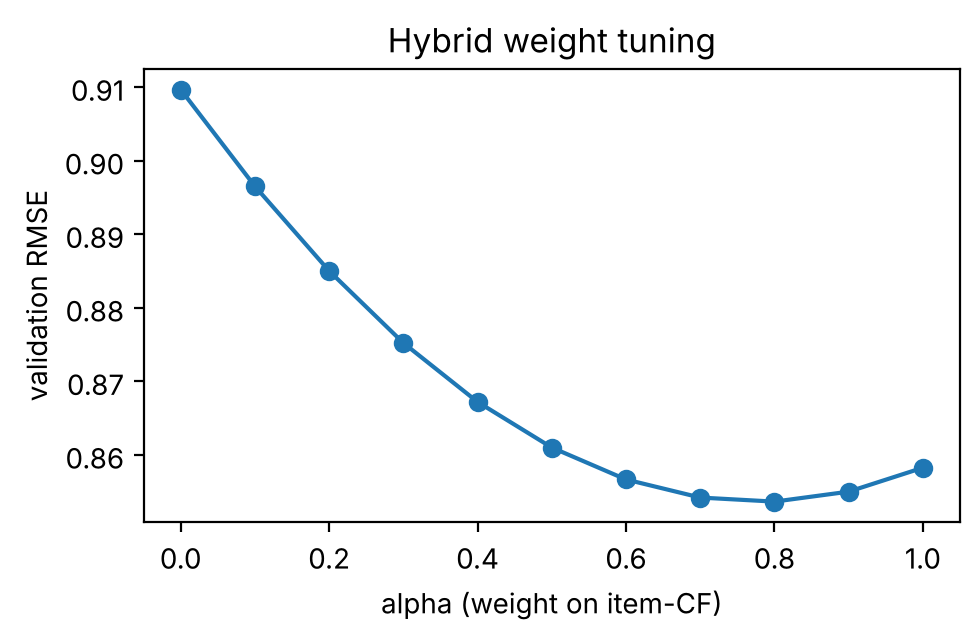

In [23]:
print(alpha_tune.to_string(index=False))
print('chosen alpha for rating prediction (lowest validation RMSE):', ALPHA, '| chosen alpha for ranking (highest validation NDCG, damped blend):', ALPHA_RANK)
plt.figure(figsize=(5, 3.3))
plt.plot(alpha_tune['alpha (CF weight)'], alpha_tune['val RMSE'], marker='o')
plt.xlabel('alpha (weight on item-CF)'); plt.ylabel('validation RMSE'); plt.title('Hybrid weight tuning')
plt.tight_layout(); plt.savefig('figures/hybrid_alpha.png', dpi=110); plt.show()

In [24]:
# (a) Simulated item cold start: hide ALL train ratings of 10% of catalogue movies
rng_c = np.random.RandomState(1)
cold_items = set(rng_c.choice(ctx_test['catalog'], size=int(0.1 * len(ctx_test['catalog'])), replace=False))
R_cold = ctx_test['R'].copy()
R_cold.loc[:, list(cold_items)] = np.nan                                 # nobody has rated them any more
mu_cold = to_matrix(train[~train.item.isin(cold_items)], users=ctx_test['R'].index).mean(axis=1)
S_cf_cold = item_cf_similarity(R_cold, mu_cold, centred=True, shrink=SHRINK)   # cold columns are all zero -> sim 0
cf_cold = item_knn_scores(R_cold, S_cf_cold, mu_cold, k=K_CF)
cb_cold = item_knn_scores(R_cold, S_cb_test, mu_cold, k=K_CB)
cb_cold_d = item_knn_scores(R_cold, S_cb_test, mu_cold, k=K_CB, damp=DAMP_CB)
hyb_cold = ALPHA * cf_cold + (1 - ALPHA) * cb_cold
# for a cold movie CF has no signal, so a sensible hybrid falls back to content alone for it:
hyb_cold_switch = hyb_cold.copy(); hyb_cold_switch[list(cold_items)] = cb_cold[list(cold_items)]
del S_cf_cold

ho_cold = ctx_test['heldout'][ctx_test['heldout'].item.isin(cold_items)]
ho_warm = ctx_test['heldout'][~ctx_test['heldout'].item.isin(cold_items)]
cs = {'user mean (fallback)': pd.DataFrame(np.repeat(mu_cold.values[:, None], R_cold.shape[1], 1), index=R_cold.index, columns=R_cold.columns),
      'item-CF': cf_cold, 'content item-kNN': cb_cold, f'content item-kNN damped (lambda={DAMP_CB})': cb_cold_d, f'hybrid alpha={ALPHA}': hyb_cold, 'hybrid, content-only for cold movies': hyb_cold_switch}
cold_tab = pd.DataFrame({n: {'RMSE cold movies': rmse(predict_pairs(s, ho_cold), ho_cold.rating),
                             'RMSE warm movies': rmse(predict_pairs(s, ho_warm), ho_warm.rating)} for n, s in cs.items()}).T
cf_used = (np.abs(predict_pairs(cf_cold, ho_cold, clip=False) - mu_cold.reindex(ho_cold.user).values) > 1e-9).mean()
print(f'cold movies: {len(cold_items)} | their test ratings: {len(ho_cold)} | warm test ratings: {len(ho_warm)}')
print(f'share of cold test pairs where item-CF returned something other than the user-mean fallback: {cf_used:.3f}')
cold_tab.round(4)

cold movies: 304 | their test ratings: 1485 | warm test ratings: 13653
share of cold test pairs where item-CF returned something other than the user-mean fallback: 0.000


,RMSE cold movies,RMSE warm movies
user mean (fallback),0.9659,0.9603
item-CF,0.9659,0.8692
content item-kNN,0.9470,0.9292
content item-kNN damped (lambda=5.0),0.9431,0.9317
hybrid alpha=0.8,0.9553,0.8653
"hybrid, content-only for cold movies",0.9470,0.8653


In [25]:
# (b) Natural cold start from the time split: test ratings on movies with NO train ratings
cold_nat = test[~test.item.isin(ctx_test['counts'].index)]
print('test ratings on movies never rated in train:', len(cold_nat), '| distinct movies:', cold_nat.item.nunique())
# content can still score them: neighbours = the user's rated catalogue movies, similarity from genres/tags
items_needed = sorted(set(ctx_test['catalog']) | set(cold_nat.item))
S_nat = content_sim(X_test, IDX_TEST, items_needed)
R_nat = ctx_test['R'].reindex(columns=items_needed)                     # cold movies are all-NaN columns
cb_nat = item_knn_scores(R_nat, S_nat, ctx_test['user_mean'], k=K_CB)
p_cb_nat = predict_pairs(cb_nat, cold_nat)
p_cbd_nat = predict_pairs(item_knn_scores(R_nat, S_nat, ctx_test['user_mean'], k=K_CB, damp=DAMP_CB), cold_nat)
tagged = cold_nat.item.isin(tags.item[~pd.Series(list(zip(tags.user, tags.item))).isin(set(zip(test.user, test.item))).values])
print(f'share of these test ratings whose movie has at least one usable (train-side) tag: {tagged.mean():.1%}')
p_um_nat = ctx_test['user_mean'].reindex(cold_nat.user).values
p_gm_nat = np.full(len(cold_nat), ctx_test['global_mean'])
print(pd.Series({'global mean': rmse(p_gm_nat, cold_nat.rating), 'user mean': rmse(p_um_nat, cold_nat.rating),
                 'content item-kNN': rmse(p_cb_nat, cold_nat.rating),
                 f'content item-kNN damped (lambda={DAMP_CB})': rmse(p_cbd_nat, cold_nat.rating), 'item-CF / SVD': np.nan},
                name='RMSE on never-seen movies').round(4).to_string())
print('item-CF and SVD have no column for these movies, so they cannot score them at all (n/a).')
del S_nat, R_nat, cb_nat

test ratings on movies never rated in train: 1688 | distinct movies: 1483


share of these test ratings whose movie has at least one usable (train-side) tag: 0.4%
global mean                             1.1867
user mean                               1.0011
content item-kNN                        1.0336
content item-kNN damped (lambda=5.0)    1.0190
item-CF / SVD                              NaN
item-CF and SVD have no column for these movies, so they cannot score them at all (n/a).


**What the cold-start experiments show.**
- **Simulated cold start (10% of catalogue movies, 304 movies, 1,485 test ratings).** Item-CF found **no** neighbour for any cold pair (share 0.000), so every prediction fell back to the user mean (RMSE 0.966). Content item-kNN can still score them, using genres and tags: 0.947, or 0.943 with damping. The plain blend (0.955) is pulled down by its CF part. Switching a cold movie to content only gives 0.947 on cold movies while keeping the hybrid's 0.865 on warm ones. That is the hybrid design to use: content for new titles, CF once ratings arrive.
- **Natural cold start (1,688 test ratings on 1,483 movies with no train ratings).** Here content does **not** beat the user mean (1.034, or 1.019 damped, against 1.001). Only 0.4% of these ratings are on movies with a usable train-side tag, so for these new movies content means genres only, and genres alone are too coarse to beat the user's own average. This is an honest negative result. A real system would need richer metadata (plot summaries, cast, keywords from TMDB through `links.csv`, as in project card P07) to help with truly new titles.

## 10. Demo
The demo model is **refitted on all ratings** (train + test). This is not evaluation any more, and refitting is what lets it promise never to recommend *any* movie the user has rated. It uses the settings chosen above. Movies are **ordered** by the damped ranking hybrid from Section 6b (`K_RANK`, `DAMP`, `ALPHA_RANK`), because that is the variant with the best validation NDCG. The **star value shown** is the plain hybrid rating prediction (item-CF with `K_CF` neighbours blended with content item-kNN using weight `ALPHA`), because that is the variant with the best RMSE. Only movies with at least `MIN_ITEM_TRAIN` ratings are recommended. Each line says why: the user's highly rated movie that is most similar to the recommendation.

Fallbacks (they come from the break-it tests in Section 11): a user with **no ratings** gets the most popular well-rated movies. A user whose ratings have **no spread** (one rating, or all the same score) gets a mean shrunk towards the global mean, so the centred ratings are not all zero.

In [26]:
class Recommender:
    """Hybrid item-CF + content recommender fitted on a ratings table (user, item, rating)."""
    def __init__(self, ratings_df, k_cf=None, k_cb=None, alpha=None, shrink=None, min_item=None, mean_shrink=5.0):
        self.k_cf, self.k_cb = k_cf or K_CF, k_cb or K_CB
        self.alpha = ALPHA if alpha is None else alpha
        self.shrink = SHRINK if shrink is None else shrink
        self.mean_shrink = mean_shrink                       # pseudo-ratings at the global mean (fix from break-it test c)
        min_item = min_item or MIN_ITEM_TRAIN
        self.ratings = ratings_df
        self.g = float(ratings_df.rating.mean())
        counts = ratings_df.groupby('item').size()
        self.catalog = sorted(counts[counts >= min_item].index)
        self.cat_set = set(self.catalog)
        R = to_matrix(ratings_df, items=self.catalog)
        plain_mean = ratings_df.groupby('user').rating.mean().reindex(R.index)
        self.S_cf = item_cf_similarity(R, plain_mean, centred=True, shrink=self.shrink)   # same as the evaluated model
        text, _ = build_item_text(exclude_pairs=None, use_tags=(CB_FEATURES != 'genres only'))
        self.vec, self.idx, self.X = fit_tfidf(text)
        self.S_cb = content_sim(self.X, self.idx, self.catalog)
        st = ratings_df.groupby('item').rating.agg(['count', 'mean'])
        self.popular = st[st['count'] >= 50].sort_values('mean', ascending=False).index   # fallback list for new users

    def shrunk_mean(self, r):
        """User mean pulled towards the global mean: (sum r + m*g) / (n + m)."""
        return (np.sum(r) + self.mean_shrink * self.g) / (len(r) + self.mean_shrink)

    def score_user(self, user_ratings):
        """user_ratings: dict {movieId: rating}. Returns (predicted ratings, best-explaining movie) for the catalogue."""
        rated = {i: r for i, r in user_ratings.items() if i in self.cat_set}
        row = pd.DataFrame([rated], columns=self.catalog, index=['u']).astype(float)
        mu = pd.Series({'u': self.shrunk_mean(list(user_ratings.values()))})
        cf = item_knn_scores(row, self.S_cf, mu, k=self.k_cf).iloc[0]
        cb = item_knn_scores(row, self.S_cb, mu, k=self.k_cb).iloc[0]
        pred = self.alpha * cf + (1 - self.alpha) * cb                         # predicted stars (RMSE model)
        cf_r = item_knn_scores(row, self.S_cf, mu, k=K_RANK, damp=DAMP).iloc[0]
        cb_r = item_knn_scores(row, self.S_cb, mu, k=self.k_cb, damp=DAMP_CB).iloc[0]
        self.last_rank_score = ALPHA_RANK * cf_r + (1 - ALPHA_RANK) * cb_r    # ranking score (damped, Section 6b)
        # explanation: among movies the user rated above their mean, the one most similar (CF, then content) to each candidate
        liked = [self.catalog.index(i) for i, r in rated.items() if r > mu['u']]
        because = pd.Series(None, index=self.catalog, dtype=object)
        if liked:
            Sx = self.alpha * self.S_cf[:, liked] + (1 - self.alpha) * self.S_cb[:, liked]
            because[:] = [self.catalog[liked[j]] for j in Sx.argmax(axis=1)]
        return pred.clip(RATING_MIN, RATING_MAX), because

    def recommend_for(self, user_ratings, n=10, verbose=True, label='this user'):
        user_ratings = dict(user_ratings)
        if len(user_ratings) == 0:                                   # break-it (a): brand-new user
            recs = [i for i in self.popular][:n]
            out = pd.DataFrame({'title': [TITLE[i] for i in recs], 'predicted': np.nan,
                                'why': 'popular with many users (no ratings yet)'})
        else:
            pred, because = self.score_user(user_ratings)
            rank = self.last_rank_score.drop(labels=[i for i in user_ratings if i in pred.index])   # NEVER recommend a rated movie
            top = rank.nlargest(n)                                                # order by the damped ranking score
            out = pd.DataFrame({'title': [TITLE[i] for i in top.index], 'predicted': pred[top.index].values.round(2),
                                'why': ['because you liked ' + TITLE[because[i]] if pd.notna(because[i]) else   # bug log #2
                                        'close to your average taste' for i in top.index]}, index=top.index)
            assert not set(out.index) & set(user_ratings), 'recommended an already-rated movie'
        if verbose:
            print(f'Top {n} for {label} ({len(user_ratings)} ratings):')
            for rank, (_, r) in enumerate(out.iterrows(), 1):
                p = '' if pd.isna(r.predicted) else f'  [{r.predicted:.2f}★]'
                print(f'  {rank:2d}. {r.title}{p}  - {r.why}')
        return out

t = time.time()
REC = Recommender(ratings)                       # demo model: all ratings
print(f'demo model fitted in {time.time() - t:.0f}s on {len(ratings)} ratings; catalogue {len(REC.catalog)} movies')

def recommend(user_id, n=10):
    """Print and return the top-n unseen movies (titles) for a MovieLens userId."""
    hist = ratings[ratings.user == user_id]
    return REC.recommend_for(dict(zip(hist.item, hist.rating)), n=n, label=f'user {user_id}')

demo model fitted in 0s on 100836 ratings; catalogue 3650 movies


In [27]:
uid = 1
hist = ratings[ratings.user == uid].sort_values('rating', ascending=False)
print(f'User {uid} rated {len(hist)} movies; some of their 5-star ones:', [TITLE[i] for i in hist[hist.rating == 5].item.head(6)])
out = recommend(uid, n=10)
print('\ncheck: recommended movies already rated by this user =', len(set(out.index) & set(hist.item)))

User 1 rated 232 movies; some of their 5-star ones: ['Seven (a.k.a. Se7en) (1995)', 'Usual Suspects, The (1995)', 'Bottle Rocket (1996)', 'Dumb & Dumber (Dumb and Dumber) (1994)', 'Billy Madison (1995)', 'Desperado (1995)']
Top 10 for user 1 (232 ratings):
   1. War of the Roses, The (1989)  [4.65★]  - because you liked Rescuers, The (1977)
   2. Bridge Too Far, A (1977)  [4.72★]  - because you liked Dirty Dozen, The (1967)
   3. Night at the Opera, A (1935)  [4.67★]  - because you liked Live and Let Die (1973)
   4. Outlaw Josey Wales, The (1976)  [4.66★]  - because you liked From Russia with Love (1963)
   5. Frost/Nixon (2008)  [4.74★]  - because you liked Dirty Dozen, The (1967)
   6. Unforgiven (1992)  [4.69★]  - because you liked Star Wars: Episode V - The Empire Strikes Back (1980)
   7. Cool Hand Luke (1967)  [4.70★]  - because you liked Monty Python and the Holy Grail (1975)
   8. Mulan (1998)  [4.75★]  - because you liked Charlotte's Web (1973)
   9. Monty Python's And Now fo

In [28]:
recommend(414, n=5);   # the heaviest rater in the dataset
print()
recommend(610, n=5);

Top 5 for user 414 (2698 ratings):
   1. Psycho (1960)  [4.32★]  - because you liked Vertigo (1958)
   2. Shining, The (1980)  [4.40★]  - because you liked Departed, The (2006)
   3. Touch of Evil (1958)  [4.21★]  - because you liked Chinatown (1974)
   4. Longest Day, The (1962)  [4.20★]  - because you liked Tora! Tora! Tora! (1970)
   5. Man Bites Dog (C'est arrivé près de chez vous) (1992)  [4.08★]  - because you liked The Shape of Water (2017)



Top 5 for user 610 (1302 ratings):
   1. Unforgiven (1992)  [4.45★]  - because you liked Good, the Bad and the Ugly, The (Buono, il brutto, il cattivo, Il) (1966)
   2. Psycho (1960)  [4.51★]  - because you liked Vertigo (1958)
   3. One Flew Over the Cuckoo's Nest (1975)  [4.55★]  - because you liked Godfather: Part II, The (1974)
   4. Fish Called Wanda, A (1988)  [4.45★]  - because you liked Evil Dead II (Dead by Dawn) (1987)
   5. This Is Spinal Tap (1984)  [4.37★]  - because you liked Star Wars: Episode V - The Empire Strikes Back (1980)


In [29]:
# Never-recommend-rated check over EVERY user (fast path: top-10 only)
bad = 0
for u, g in ratings.groupby('user'):
    rec = REC.recommend_for(dict(zip(g.item, g.rating)), n=10, verbose=False)
    bad += len(set(rec.index) & set(g.item))
print('already-rated movies recommended, summed over all', ratings.user.nunique(), 'users:', bad)

already-rated movies recommended, summed over all 610 users: 0


## 11. Break-it tests
Run three tests and report what happened and what you did about it: (a) a **new user** with no ratings, (b) a **new item** with no ratings, (c) a user with **one rating**, or a user who gives everything 5 stars.

In [30]:
print('=== (a) brand-new user, no ratings ===')
recommend(999999, n=5)
print('\nWhat CF alone does for this user: no ratings -> no neighbours, the user mean is undefined:',
      to_matrix(ratings).reindex([999999]).mean(axis=1).iloc[0])

=== (a) brand-new user, no ratings ===
Top 5 for user 999999 (0 ratings):
   1. Shawshank Redemption, The (1994)  - popular with many users (no ratings yet)
   2. Godfather, The (1972)  - popular with many users (no ratings yet)
   3. Fight Club (1999)  - popular with many users (no ratings yet)
   4. Cool Hand Luke (1967)  - popular with many users (no ratings yet)
   5. Dr. Strangelove or: How I Learned to Stop Worrying and Love the Bomb (1964)  - popular with many users (no ratings yet)

What CF alone does for this user: no ratings -> no neighbours, the user mean is undefined: nan


In [31]:
print('=== (b) brand-new movie with text only (no ratings) ===')
new_text = 'genre_sci_fi genre_action space aliens dystopia'
v = REC.vec.transform([new_text])
sims = pd.Series(cosine_similarity(v, REC.X[REC.idx.get_indexer(REC.catalog)]).ravel(), index=REC.catalog)
print('closest catalogue movies by content:', [TITLE[i] for i in sims.nlargest(5).index])
print('item-CF similarity of the new movie to every catalogue movie: all zero (no co-ratings) -> CF prediction = user mean')
# predicted rating for two users: content item-kNN using the user's ratings on the content neighbours
for u in [1, 610]:
    h = ratings[ratings.user == u]
    ur = h.set_index('item').rating.reindex(REC.catalog)
    s = sims.copy(); s[ur.isna()] = 0; top = s.nlargest(REC.k_cb); top = top[top > 0]
    mu = REC.shrunk_mean(h.rating.values)
    pred = mu + (top * (ur[top.index] - mu)).sum() / top.sum() if len(top) else mu
    print(f'user {u}: user mean {mu:.2f} -> content prediction for the new movie {pred:.2f} (from {len(top)} content neighbours)')

=== (b) brand-new movie with text only (no ratings) ===
closest catalogue movies by content: ['Men in Black (a.k.a. MIB) (1997)', 'Arrival, The (1996)', 'Armageddon (1998)', 'Independence Day (a.k.a. ID4) (1996)', 'Day the Earth Stood Still, The (1951)']
item-CF similarity of the new movie to every catalogue movie: all zero (no co-ratings) -> CF prediction = user mean
user 1: user mean 4.35 -> content prediction for the new movie 4.15 (from 40 content neighbours)
user 610: user mean 3.69 -> content prediction for the new movie 3.62 (from 40 content neighbours)


In [32]:
toy = movies.loc[movies.title == 'Toy Story (1995)', 'item'].iloc[0]
def tie_report(user_ratings, shrink):
    REC.mean_shrink = shrink
    pred, _ = REC.score_user(user_ratings)
    rank = REC.last_rank_score.drop(labels=list(user_ratings), errors='ignore')
    top = rank.nlargest(10)
    return {'mean used': round(float(REC.shrunk_mean(list(user_ratings.values()))), 3),
            'distinct predicted stars': int(pred.round(6).nunique()),
            'distinct ranking scores': int(rank.round(6).nunique()),
            'movies tied with the #1 score': int((rank.round(6) == round(top.iloc[0], 6)).sum())}

print('=== (c1) a user with ONE rating (Toy Story = 5 stars) ===')
print('before fix (plain mean)          :', tie_report({toy: 5.0}, 0.0))
print('after fix (mean shrunk, m = 5)   :', tie_report({toy: 5.0}, 5.0))
REC.mean_shrink = 0.0
REC.recommend_for({toy: 5.0}, n=5, label='one-rating user, BEFORE fix')
REC.mean_shrink = 5.0
REC.recommend_for({toy: 5.0}, n=5, label='one-rating user, AFTER fix');

=== (c1) a user with ONE rating (Toy Story = 5 stars) ===
before fix (plain mean)          : {'mean used': 5.0, 'distinct predicted stars': 1, 'distinct ranking scores': 1, 'movies tied with the #1 score': 3649}


after fix (mean shrunk, m = 5)   : {'mean used': 3.751, 'distinct predicted stars': 5, 'distinct ranking scores': 2120, 'movies tied with the #1 score': 1}


Top 5 for one-rating user, BEFORE fix (1 ratings):
   1. Jumanji (1995)  [5.00★]  - close to your average taste
   2. Grumpier Old Men (1995)  [5.00★]  - close to your average taste
   3. Waiting to Exhale (1995)  [5.00★]  - close to your average taste
   4. Father of the Bride Part II (1995)  [5.00★]  - close to your average taste
   5. Heat (1995)  [5.00★]  - close to your average taste
Top 5 for one-rating user, AFTER fix (1 ratings):
   1. Toy Story 2 (1999)  [5.00★]  - because you liked Toy Story (1995)
   2. Toy Story 3 (2010)  [5.00★]  - because you liked Toy Story (1995)
   3. Aladdin (1992)  [5.00★]  - because you liked Toy Story (1995)
   4. Wallace & Gromit: The Wrong Trousers (1993)  [5.00★]  - because you liked Toy Story (1995)
   5. Monsters, Inc. (2001)  [5.00★]  - because you liked Toy Story (1995)


In [33]:
print('=== (c2) a user who gives everything 5 stars (15 popular movies) ===')
all5 = {i: 5.0 for i in list(REC.popular[:15])}
print('before fix:', tie_report(all5, 0.0))
print('after fix :', tie_report(all5, 5.0))
REC.mean_shrink = 5.0
REC.recommend_for(all5, n=5, label='all-5-stars user (after fix)');

# Does the shrunk mean hurt normal users?  Check item-CF on the VALIDATION split with shrunk vs plain user means
g_in = train_in.rating.mean()
st = train_in.groupby('user').rating.agg(['sum', 'count'])
mu_shr = ((st['sum'] + 5 * g_in) / (st['count'] + 5)).reindex(ctx_val['R'].index)
S_tmp = item_cf_similarity(ctx_val['R'], ctx_val['user_mean'], centred=True, shrink=SHRINK)
for nm, m in [('plain user mean', ctx_val['user_mean']), ('shrunk user mean (m=5)', mu_shr)]:
    r = results_row('', item_knn_scores(ctx_val['R'], S_tmp, m, k=K_CF), ctx_val)
    print(f'validation item-CF with {nm:22s}: RMSE {r["RMSE"]:.4f} | NDCG@{K_EVAL} {r[f"ndcg@{K_EVAL}"]:.4f}')
del S_tmp

=== (c2) a user who gives everything 5 stars (15 popular movies) ===


before fix: {'mean used': 5.0, 'distinct predicted stars': 1, 'distinct ranking scores': 1, 'movies tied with the #1 score': 3635}


after fix : {'mean used': 4.625, 'distinct predicted stars': 4, 'distinct ranking scores': 3079, 'movies tied with the #1 score': 1}


Top 5 for all-5-stars user (after fix) (15 ratings):
   1. Star Wars: Episode V - The Empire Strikes Back (1980)  [5.00★]  - because you liked Star Wars: Episode IV - A New Hope (1977)
   2. Reservoir Dogs (1992)  [5.00★]  - because you liked Goodfellas (1990)
   3. Pulp Fiction (1994)  [5.00★]  - because you liked Fight Club (1999)
   4. Apocalypse Now (1979)  [5.00★]  - because you liked Goodfellas (1990)
   5. Good, the Bad and the Ugly, The (Buono, il brutto, il cattivo, Il) (1966)  [5.00★]  - because you liked Godfather, The (1972)


validation item-CF with plain user mean       : RMSE 0.8583 | NDCG@5 0.0123


validation item-CF with shrunk user mean (m=5): RMSE 0.8582 | NDCG@5 0.0123


**Break-it results and what was done.**

| Test | What happened | What I did |
|---|---|---|
| (a) brand-new user, no ratings | CF has no neighbours and the user mean is undefined (`NaN`). | `recommend()` falls back to the highest-rated movies among those with at least 50 ratings, and labels them as such. Weakness: everyone gets the same list. An onboarding "rate 5 movies" step would fix that. |
| (b) brand-new movie, text only | Item-CF similarity to every movie is 0, so CF can only return the user mean. Content finds sensible neighbours (*Men in Black*, *Armageddon*, *Independence Day* …) and gives user-specific predictions (user 1: 4.15 vs mean 4.35; user 610: 3.62 vs mean 3.69). | Content is used for new movies (Section 9 hybrid switch). |
| (c1) one rating (Toy Story = 5) | **Broke.** The centred rating is 5 − 5 = 0, so all 3,649 catalogue movies tied at 5.0 and the top 5 were just the lowest movieIds (*Jumanji*, *Grumpier Old Men* …). The explanation code also crashed (bug log #2). | User mean shrunk towards the global mean with 5 pseudo-ratings (mean 3.751), so the one rating becomes a positive signal. After the fix: 2,120 distinct ranking scores, 1 movie at the top, and the top 5 are *Toy Story 2*, *Toy Story 3*, *Aladdin* … |
| (c2) all 5-star user (15 movies) | Same tie: 3,635 movies tied for first place. | Same fix: mean 4.625, 3,079 distinct scores, 1 at the top. Check on validation that the fix does not hurt normal users: item-CF RMSE 0.8583 (plain mean) vs 0.8582 (shrunk). |

The star values shown still sit at 5.00 for these extreme users. Every neighbour has the same deviation, so the weighted average is that deviation, and the result is clipped at 5. The **ordering** is what the fix repairs.

## 12. By-hand check
Pick one prediction from your collaborative model. Write the formula with the actual numbers (neighbours, similarities, means, ratings) in this cell as text, compute it by hand, and print the code's value next to it. They should match up to rounding.

**Chosen prediction (from the final item-CF model, k = 40, centred cosine, fitted on train):** user **114**, movie **Spider-Man 3 (2007)**, a real test pair (true held-out rating 4.5). The code below picks it automatically (first test pair whose user has only 3 or 4 positively similar rated movies with different ratings) and prints every number used.

User 114's train mean: 25 ratings summing to 85.5, so $\bar r_{114} = 85.5 / 25 = 3.42$.

Of the movies user 114 rated, only three have a positive similarity to *Spider-Man 3*, so all three are used (k = 40 is not reached):

| neighbour j | s(i, j) | r_{114,j} | r − 3.42 | s × (r − 3.42) |
|---|---|---|---|---|
| Amazing Spider-Man, The (2012) | 0.033041 | 0.5 | −2.92 | −0.096480 |
| Wolf of Wall Street, The (2013) | 0.027367 | 4.5 | +1.08 | +0.029556 |
| Spider-Man 2 (2004) | 0.022044 | 4.5 | +1.08 | +0.023808 |
| **sum** | **0.082452** | | | **−0.043116** |

$$\hat r_{114,\ \text{Spider-Man 3}} = 3.42 + \frac{-0.043116}{0.082452} = 3.42 - 0.52292 = \mathbf{2.8971}$$

**Code value: 2.8971.** They match (difference about 1e-8, from float32 similarities). This example also shows a weakness: three very weak similarities (all below 0.04) decide the whole prediction. One 0.5-star rating of *The Amazing Spider-Man* pulls the prediction to 2.90 while the user actually gave 4.5. That is exactly the kind of low-evidence prediction the damped ranking variant (Section 6b) shrinks towards the mean.

In [34]:
def explain_item_cf(R, S, user_mean, u, i, k):
    """Single-pair version of item_knn_scores that also returns the neighbours used (for the by-hand check)."""
    cols = list(R.columns); ii = cols.index(i)
    r_u = R.loc[u].dropna().drop(labels=[i], errors='ignore')
    s = pd.Series(S[ii, [cols.index(j) for j in r_u.index]], index=r_u.index)
    s = s[s > 0].nlargest(k)
    mu = user_mean[u]
    tab = pd.DataFrame({'neighbour': [TITLE[j] for j in s.index], 'sim s(i,j)': s.values,
                        'r_uj': r_u[s.index].values, 'r_uj - mean_u': r_u[s.index].values - mu})
    pred = mu + (s * (r_u[s.index] - mu)).sum() / s.abs().sum()
    return tab, mu, pred

# A real test pair from the final item-CF model (k = K_CF). So that the sum fits on paper, take the first test pair
# (ordered by user, then movie) whose user has only 3 or 4 rated movies with a positive similarity to the target.
# The neighbours must also have different ratings, otherwise the weighted average is trivial.
def pos_neighbour_ratings(u, i):
    ii = ctx_test['R'].columns.get_loc(i)
    row = ctx_test['R'].loc[u].values
    rated = np.flatnonzero(~np.isnan(row))
    return row[rated[S_cf_test[ii, rated] > 0]]
for _, pair in ctx_test['heldout'].sort_values(['user', 'item']).iterrows():
    nb = pos_neighbour_ratings(int(pair['user']), int(pair['item']))
    if 3 <= len(nb) <= 4 and len(set(nb)) > 1:
        break
u, i = int(pair['user']), int(pair['item'])     # pair.item would be the pandas .item() METHOD (bug log #1)
tab, mu, pred_hand_code = explain_item_cf(ctx_test['R'], S_cf_test, ctx_test['user_mean'], u, i, K_CF)
print(f'user {u}, movie {i} = {TITLE[i]} | true held-out rating {pair.rating} | user mean (train) {mu:.4f} | k = {K_CF}')
print(tab.to_string(index=False, float_format=lambda x: f'{x:.6f}'))
num = (tab['sim s(i,j)'] * tab['r_uj - mean_u']).sum(); den = tab['sim s(i,j)'].abs().sum()
print(f'\nuser mean to 6 decimals: {mu:.6f}')
print(f'numerator   sum s*(r - mean) = {num:.6f}')
print(f'denominator sum |s|          = {den:.6f}')
print(f'by hand: {mu:.4f} + {num:.4f} / {den:.4f} = {mu + num / den:.4f}')
print(f'code (item_knn_scores, used for the results table): {cf_test.loc[u, i]:.4f}')
print(f'absolute difference: {abs(mu + num / den - cf_test.loc[u, i]):.2e}  (float32 similarities vs float64 arithmetic)')
print(f'user {u} rated {ctx_test["R"].loc[u].notna().sum()} catalogue movies in train; all ratings of user {u} in train:', 
      train[train.user == u].rating.round(1).tolist()[:30], '...' if (train.user == u).sum() > 30 else '')

user 114, movie 52722 = Spider-Man 3 (2007) | true held-out rating 4.5 | user mean (train) 3.4200 | k = 40
                      neighbour  sim s(i,j)     r_uj  r_uj - mean_u
 Amazing Spider-Man, The (2012)    0.033041 0.500000      -2.920000
Wolf of Wall Street, The (2013)    0.027367 4.500000       1.080000
            Spider-Man 2 (2004)    0.022044 4.500000       1.080000

user mean to 6 decimals: 3.420000
numerator   sum s*(r - mean) = -0.043116
denominator sum |s|          = 0.082452
by hand: 3.4200 + -0.0431 / 0.0825 = 2.8971
code (item_knn_scores, used for the results table): 2.8971
absolute difference: 1.27e-08  (float32 similarities vs float64 arithmetic)
user 114 rated 22 catalogue movies in train; all ratings of user 114 in train: [3.5, 3.0, 3.5, 4.0, 4.0, 4.0, 4.0, 4.5, 3.5, 3.5, 4.0, 3.5, 2.0, 3.5, 3.0, 2.5, 0.5, 4.5, 3.0, 2.5, 3.5, 3.5, 5.0, 3.5, 3.5] 


## 13. Understanding pack
**13a. Deliberate-leak experiment.** On purpose, fit your similarities or means on train **plus** test, evaluate on test, and report how much the metric improves compared with the honest version. This shows you know what leakage looks like. Result: item-CF RMSE **0.8662 (honest)** vs **0.5666 (leaky)**, which looks 34.6% better. NDCG@5 is 0.0190 (honest) vs 0.2007 (leaky), about 10×. For SVD, RMSE is 0.9324 (honest) vs 0.8620 (leaky) and NDCG@5 0.0848 vs 0.1188. The leaky user means already contain the test rating, and the leaky similarities "know" which movies each user rated together in the test period. Nothing in the leaky code errors or looks wrong. Only the comparison with the honest number shows the problem, which is why the split comes first.

In [35]:
# LEAKY on purpose: means and item similarities computed from train + test (all ratings), then "predict" the test ratings.
# Neighbour ratings still come from train, exactly as in the lab's Deliberate error 3.
R_full = to_matrix(ratings, users=ctx_test['R'].index, items=ctx_test['catalog'])
mean_leak = to_matrix(ratings, users=ctx_test['R'].index).mean(axis=1)
S_leak = item_cf_similarity(R_full, mean_leak, centred=True, shrink=SHRINK)
cf_leak = item_knn_scores(ctx_test['R'], S_leak, mean_leak, k=K_CF)
del S_leak
# Leaky SVD: factorise the matrix that already contains the test ratings
svd_leak = svd_scores(to_matrix(ratings, users=ctx_test['R'].index, items=sorted(ratings.item.unique())), k=K_SVD)[ctx_test['catalog']]

leak = pd.DataFrame([results_row('item-CF honest', cf_test, ctx_test), results_row('item-CF LEAKY (sims + means on train+test)', cf_leak, ctx_test),
                     results_row(f'SVD k={K_SVD} honest', svd_test, ctx_test), results_row(f'SVD k={K_SVD} LEAKY (fit on train+test)', svd_leak, ctx_test)]
                    ).set_index('model')[['RMSE', f'precision@{K_EVAL}', f'ndcg@{K_EVAL}']]
print(leak.round(4))
for m in ['item-CF', f'SVD k={K_SVD}']:
    h, l = leak.loc[[x for x in leak.index if x.startswith(m) and 'honest' in x][0]], leak.loc[[x for x in leak.index if x.startswith(m) and 'LEAKY' in x][0]]
    print(f'{m}: RMSE {h.RMSE:.4f} -> {l.RMSE:.4f} ({(h.RMSE - l.RMSE) / h.RMSE:+.1%} better-looking) | NDCG@{K_EVAL} {h[f"ndcg@{K_EVAL}"]:.4f} -> {l[f"ndcg@{K_EVAL}"]:.4f}')

                                              RMSE  precision@5  ndcg@5
model                                                                  
item-CF honest                              0.8662       0.0205  0.0190
item-CF LEAKY (sims + means on train+test)  0.5666       0.1836  0.2007
SVD k=5 honest                              0.9324       0.0778  0.0848
SVD k=5 LEAKY (fit on train+test)           0.8620       0.1078  0.1188
item-CF: RMSE 0.8662 -> 0.5666 (+34.6% better-looking) | NDCG@5 0.0190 -> 0.2007
SVD k=5: RMSE 0.9324 -> 0.8620 (+7.5% better-looking) | NDCG@5 0.0848 -> 0.1188


**13b. Decision log** (all evidence from the **validation** split cut from train, unless marked *test*)

| Decision | Alternatives I tried | Evidence (a number) | Chosen |
|---|---|---|---|
| Train/test split | random split (3 seeds) vs time-based (latest 20% per user) | random overstates: most-popular NDCG@5 0.1755 ± 0.0060 vs 0.0800; SVD 0.1618 vs 0.0848; item-CF RMSE 0.8343 vs 0.8662 (*test*) | time-based |
| Item-CF similarity | raw cosine with gaps = 0 vs mean-centred cosine | best val RMSE: raw 0.8748 (k = 20) vs centred 0.8583 (k = 40); *test* RMSE 0.8938 vs 0.8662 | centred cosine |
| k neighbours (item-CF, RMSE model) | k = 5, 10, 20, 40, 80 | val RMSE 0.8960, 0.8718, 0.8607, 0.8583, 0.8594 | 40 |
| Similarity shrinkage β | β = 0, 10, 25, 50, 100 | val RMSE 0.8583, 0.8599, 0.8614, 0.8626, 0.8632 | 0 (no shrinkage) |
| Catalogue threshold (min train ratings per movie) | 3, 5, 10 | val RMSE on the same pairs 0.8503, 0.8497, 0.8503; similarity matrix 51.1, 27.0, 9.5 MB | 5 |
| Content features | genres only vs genres + tags (k = 10 to 80) | best val RMSE 0.9136 vs 0.9097; NDCG@5 at k = 40: 0.0052 vs 0.0085 | genres + tags, k = 40 |
| SVD rank | k = 2, 5, 10, 20, 50 | val RMSE 0.9155, 0.9143, 0.9146, 0.9170, 0.9241 (NDCG@5 is best at k = 20: 0.0915, a trade-off) | 5 (chosen by RMSE) |
| Ranking: damping λ and k | λ = 0, 1, 2, 5, 10, 20 × k = 10, 20, 40 | k = 20: NDCG@5 0.0191 (λ = 0) → 0.0810 (λ = 5) → 0.0813 (λ = 10); RMSE 0.8607 → 0.9036 | k = 20, λ = 10 for ranking |
| Hybrid weight α | α = 0, 0.1, …, 1 | val RMSE 0.9097 (content only), 0.8537 (α = 0.8), 0.8583 (CF only); damped blend NDCG@5 best 0.0822 at α = 0.9 | α = 0.8 (stars), 0.9 (ranking) |
| User-mean shrinkage in the demo | plain mean vs (sum + 5·g)/(n + 5) | val RMSE 0.8583 vs 0.8582; fixes the one-rating tie (3,649 → 1 tied at top) | shrunk, m = 5 |

**13c. Bug log** (real problems hit while building this notebook)

| What went wrong | How I found it | Fix | Before and after |
|---|---|---|---|
| By-hand cell crashed: `int(pair.item)` raised `TypeError: int() argument must be ... not 'method'`. On a pandas row, `.item` is the Series **method** `item()`, not the column called `item`. | The notebook stopped with an error in Section 12 on the first full run. | Use `pair['item']` (and `pair['user']`) for column access. | Before: crash, no by-hand value. After: by-hand 2.8971 = code 2.8971. |
| Explanations crashed with `KeyError: nan` for a user with no above-average rating (the one-rating break-it user). The "because" Series was filled with NaN, but the code tested `is not None`. | Break-it test (c1) stopped with an error on the first full run. | Test with `pd.notna(...)` and fall back to "close to your average taste". | Before: crash. After: the list prints for every user, and 0 already-rated movies are recommended over all 610 users. |
| Item-CF ranked poorly: test NDCG@5 **0.0190**, far below most popular (0.0800). User 1's first demo list was obscure titles such as *Sicko (2007)* and *Girlfight (2000)*, predicted at 4.8 stars. Cause: the normalised formula lets one weak neighbour produce a top prediction. | Comparing the results table with the most-popular baseline, then reading the demo output. | Damped denominator Σs + λ (Section 6b), tuned on validation NDCG. | Test NDCG@5 0.0190 → 0.0696 (item-CF) and 0.0724 (hybrid). User 1's list now starts with *War of the Roses*, *A Bridge Too Far* … |
| One-rating and all-5 users got a fully tied ranking (every centred rating = 0). | Break-it test (c). | Shrink the user mean towards the global mean (m = 5). | 3,649 movies tied at the top → 1. |

## 14. AI-use log
> **You must complete this section yourself.** The rows below record honestly what the AI produced. The column *What I checked or changed* must describe what **you** did when you went through the notebook. Edit it in your own words. Your professor's rule is that you can explain every line and re-derive the by-hand check.

| Task | Tool | What the AI produced | What I checked or changed |
|---|---|---|---|
| Reading the brief and the data | Claude (Anthropic) | Read the project PDF, the starter notebook and the four CSV files. Checked their shapes, missing values, duplicate pairs and rating scale with pandas. | *TODO (you): open the CSVs and confirm the printed counts (610 users, 9,724 rated movies, 100,836 ratings).* |
| Pipeline code (Sections 2 to 10) | Claude | All code cells, reusing the starter helpers unchanged, and added `item_knn_scores`, `results_row` and the `Recommender` class. | *TODO (you): re-run top to bottom; explain `item_knn_scores` line by line.* |
| Tuning and evaluation | Claude | Validation split, tuning grids, results table, bootstrap intervals, random-vs-time split. | *TODO (you): check that no tuning cell uses `test`, and say why.* |
| By-hand check | Claude + you | Picked the pair, printed every number. | *TODO (you): redo the Section 12 sum on paper and confirm 2.8971.* |
| README and CV bullet | Claude | Drafts using numbers from this notebook. | *TODO (you): check every number against the outputs.* |

**One thing the AI got wrong (and how I caught it):** The AI's first version of the by-hand cell used `pair.item`, which in pandas is the `.item()` method, so the cell crashed. Its first item-CF ranking model also produced obscure recommendations (NDCG@5 0.019 vs 0.080 for most popular). Both were caught by running the notebook and comparing against the baseline, not by reading the code. *(Rewrite in your own words, and add anything you caught yourself.)*

**What I would do with 100 times more data:** With about 10 M ratings a dense users × movies table no longer fits in memory. I would keep everything in `scipy.sparse`, keep only the top-50 neighbours per movie (or use approximate nearest-neighbour search, as in project card P18), and replace the simple SVD with ALS or FunkSVD fitted only on observed ratings. More data would also make the time split and the per-segment results (light vs heavy users) much more reliable.

**How industry systems extend this project:** Production recommenders work in stages. Retrieval narrows millions of items to hundreds, using item-item CF or two-tower embeddings. A learned ranking model then scores those candidates using many features (context, recency, watch time). A re-ranking stage adds rules, diversity and freshness, and the whole system is judged by online A/B tests on clicks and watch time, which this offline project could not do.

In [36]:
print(f'Notebook finished in {(time.time() - T0) / 60:.1f} minutes.')
print('Key settings:', dict(MIN_ITEM_TRAIN=MIN_ITEM_TRAIN, K_CF=K_CF, SHRINK=SHRINK, K_CB=K_CB, CB_FEATURES=CB_FEATURES, K_SVD=K_SVD, ALPHA=ALPHA))
results.round(4).to_csv('figures/results_table.csv')

Notebook finished in 5.1 minutes.
Key settings: {'MIN_ITEM_TRAIN': 5, 'K_CF': 40, 'SHRINK': 0, 'K_CB': 40, 'CB_FEATURES': 'genres + tags', 'K_SVD': 5, 'ALPHA': 0.8}


---
## README template (copy into README.md)
The filled README is delivered as `README.md` next to this notebook.